# Revisión sistemática — Resultados descriptivos según el PICO
**Análisis geoespacial de patrones y factores ambientales asociados a los cambios en ecosistemas forestales**
Grupo 10 · Estadística Espacial · UNA Puno · Docente: Fred Torres Cruz · Octubre 2026

**Pregunta de la revisión.** ¿Qué técnicas de análisis geoespacial identifican patrones espaciales de cambios en ecosistemas forestales, qué factores ambientales se asocian y cómo se manejan la escala, la resolución y la calidad de los datos?

El notebook está organizado por el PICO y cada bloque termina con **una respuesta a la sub-pregunta** generada desde los datos:

| Bloque | Variables de la matriz | Sub-pregunta |
|---|---|---|
| **A. Corpus** | id_estudio … plataforma, anio | ¿Qué se incluyó y qué tan completo está el dato? |
| **P. Población** | fenomeno, pais_iso3, pais, continente, peru, area_estudio | ¿Qué fenómeno y dónde se estudia? |
| **I. Intervención** | tecnica_ppal, metodo, tecnicas_secundarias, tipo_problema, tecnica_resumen, motor_ppal, motores_datos | ¿Qué técnica y qué motor de datos se usan más? |
| **O. Resultados** | estad_patron, patron, dependencia, factores, factor_principal, asociacion, tec_validacion, prop_validacion, metrica, valor_metrica, metrica_otra, rango_valor, calidad_global, resultado_principal, observaciones | ¿Qué patrones, qué factores, cómo se valida, qué desempeño y qué calidad? |
| **Escala, resolución y calidad de datos** | motor_ppal, patron, observaciones | Tercera parte de la pregunta |

**Lectura de los porcentajes.** Cada tabla muestra `n`, `% de N` (N = estudios de la base de esa tabla: 96 en el total, 64 en validación, etc.) y `% de reportados` (excluye NR). Los porcentajes se redondean **half-up** (12,5 → 13; 37,5 → 38). Las categorías *No aplica / No evaluado / No analiza* son **respuestas válidas** de la ficha (no son datos faltantes); **NR** sí es dato faltante. Donde corresponde, el denominador se restringe a los estudios a los que la variable aplica (p. ej. validación solo en estudios con modelo).

**Alineación con el PICO (correcciones de revisión).**
- *Intervención*: el PICO define 4 técnicas (patrones de puntos, autocorrelación, interpolación, SIG = **núcleo PICO**). El corpus incluye además clasificación/detección de cambios, machine learning, regresión espacial y otra (**ampliación**). El cuaderno separa ambos grupos y la ampliación debe **justificarse o incorporarse en el PICO**.
- *Factores*: el PICO menciona hidroclimáticos, topográficos y de cobertura; la matriz agrega *Antrópicos* y *Edáficos*. Se señala qué grupos están en el PICO y cuáles no.
- *Bases de datos*: la columna `plataforma` es la **editorial** de origen (ScienceDirect, MDPI…), **no** las bases de búsqueda. Según el PICO, la búsqueda se hizo en Scopus, Web of Science y SciELO.
- *Periodo*: 2021–2026 no figura en el PICO; debe documentarse en el protocolo. 2026 está incompleto (búsqueda 11–12/10/2026).

**Uso:** deja `Grupo10_Matriz_v4_96estudios.xlsx` junto al notebook (o cambia `RUTA`) y ejecuta todo.

In [1]:
import re, warnings
import pandas as pd, numpy as np, matplotlib.pyplot as plt
from IPython.display import display, Markdown
warnings.filterwarnings('ignore')
pd.set_option('display.max_colwidth', 90); pd.set_option('display.width', 180); pd.set_option('display.max_rows', 200)
plt.rcParams.update({'figure.dpi':110,'axes.spines.top':False,'axes.spines.right':False,'axes.grid':True,
                     'grid.alpha':.25,'axes.axisbelow':True,'font.size':9})
AZUL, CLARO, GRIS, ROJO = '#2E6F9E', '#9CC3DE', '#B8C0C8', '#C0504D'

RUTA = 'Grupo10_Matriz_v4_96estudios.xlsx'   # <- ajusta si hace falta
df = pd.read_excel(RUTA, sheet_name='Matriz', header=1)   # fila 1 = bandas PICO, fila 2 = nombres de columna
N = len(df)
TABLAS = {}      # aquí se guardan las tablas para exportarlas al final
print(f'{N} estudios x {df.shape[1]} columnas')

FileNotFoundError: [Errno 2] No such file or directory: 'Grupo10_Matriz_v4_96estudios.xlsx'

## 0. Control de calidad de la matriz
Antes de calcular, se verifica que la matriz coincide con el PRISMA y que respeta las reglas de llenado de la Ficha.

In [ ]:
# --- 0.1 Coincidencia con el PRISMA ---
prisma = {'P1':25,'P2':30,'P3':17,'P4':24}
obs = df.integrante.value_counts().to_dict()
chk = pd.DataFrame({'PRISMA':prisma, 'Matriz':{k:obs.get(k,0) for k in prisma}})
chk['OK'] = chk.PRISMA == chk.Matriz
display(chk)
assert N == 96 and df.id_estudio.is_unique
print('Estudios:', N, '| IDs únicos:', df.id_estudio.is_unique, '| Perú (peru=Sí):', (df.peru=='Sí').sum(), '(PRISMA: 11)')
print('Años:', df.anio.min(), '–', df.anio.max(), '(ventana: 2021–2026) →', 'OK' if df.anio.between(2021,2026).all() else 'REVISAR')
print('Nota: el periodo 2021–2026 no está en el PICO (documentarlo en el protocolo); 2026 incompleto (búsqueda 11–12/10/2026).')

,PRISMA,Matriz,OK
P1,25,25,True
P2,30,30,True
P3,17,17,True
P4,24,24,True


Estudios: 96 | IDs únicos: True | Perú (peru=Sí): 11 (PRISMA: 11)
Años: 2021 – 2026 (ventana: 2021–2026) → OK
Nota: el periodo 2021–2026 no está en el PICO (documentarlo en el protocolo); 2026 incompleto (búsqueda 11–12/10/2026).


In [ ]:
# --- 0.2 Reglas de llenado de la Ficha: cada regla devuelve los estudios que la incumplen ---
def umbral(m, v):
    if pd.isna(v): return None
    if m=='AUC':   return 'Bajo' if v<.70 else 'Aceptable' if v<.80 else 'Bueno' if v<.90 else 'Excelente'
    if m=='Kappa': return 'Débil' if v<=.40 else 'Moderado' if v<=.60 else 'Sustancial' if v<=.80 else 'Casi perfecto'
    if m in ('R²','F1'): return 'Bajo' if v<.50 else 'Moderado' if v<.70 else 'Alto'
    if m=='Exactitud global': return 'Cumple el umbral' if v>=.85 else 'Bajo el umbral'
df['_v'] = pd.to_numeric(df.valor_metrica, errors='coerce')
rec = df.apply(lambda r: umbral(r.metrica, r._v), axis=1)
usan_stat = df.estad_patron.isin(['Moran global','LISA','Getis-Ord Gi*'])

reglas = {
 'R1  estad_patron = Ninguno  →  patron = No evaluado':           (df.estad_patron=='Ninguno') & (df.patron!='No evaluado'),
 'R2  sin Moran/LISA/Gi*  →  dependencia = No evaluada (o NR)':    (~usan_stat) & ~df.dependencia.isin(['No evaluada','NR']),
 'R3  Descriptivo  →  tec_validacion = No aplica (descriptivo)':   (df.tipo_problema=='Descriptivo') & (df.tec_validacion!='No aplica (descriptivo)'),
 'R4  factores = No analiza  ⇔  factor_principal = No aplica':     (df.factores=='No analiza factores') != (df.factor_principal=='No aplica'),
 'R5  peru = Sí  ⇔  pais_iso3 = PER':                              (df.peru=='Sí') != (df.pais_iso3=='PER'),
 'R6  rango_valor coincide con los umbrales (AUC/Kappa/R²/F1/Exactitud)': rec.notna() & (rec != df.rango_valor),
 'R7  usa Moran/LISA/Gi*  →  dependencia ≠ No evaluada':                  usan_stat & (df.dependencia=='No evaluada'),
}
# Informativo (no es incumplimiento de la ficha, es vacío de extracción): estudios con Moran/LISA/Gi* sin dependencia extraída
nr_dep = int((usan_stat & (df.dependencia.fillna('NR')=='NR')).sum())
print(f'Estudios con Moran/LISA/Gi*: {int(usan_stat.sum())} | con dependencia reportada: {int((usan_stat & ~df.dependencia.fillna("NR").isin(["NR","No evaluada"])).sum())} | en NR: {nr_dep}')
res = pd.DataFrame({'incumplen': {k:int(v.sum()) for k,v in reglas.items()}})
display(res)
TABLAS['0_reglas_ficha'] = res
for k,v in reglas.items():
    if v.any():
        print('\n▸', k); display(df.loc[v, ['id_estudio','integrante','tecnica_ppal','estad_patron','patron','dependencia','tipo_problema','tec_validacion','metrica','valor_metrica','rango_valor','factores','factor_principal','peru','pais_iso3']].head(12))

Estudios con Moran/LISA/Gi*: 11 | con dependencia reportada: 3 | en NR: 8


,incumplen
R1 estad_patron = Ninguno → patron = No evaluado,0
R2 sin Moran/LISA/Gi* → dependencia = No evaluada (o NR),1
R3 Descriptivo → tec_validacion = No aplica (descriptivo),1
R4 factores = No analiza ⇔ factor_principal = No aplica,0
R5 peru = Sí ⇔ pais_iso3 = PER,0
R6 rango_valor coincide con los umbrales (AUC/Kappa/R²/F1/Exactitud),0
R7 usa Moran/LISA/Gi* → dependencia ≠ No evaluada,0



▸ R2  sin Moran/LISA/Gi*  →  dependencia = No evaluada (o NR)


,id_estudio,integrante,tecnica_ppal,estad_patron,patron,dependencia,tipo_problema,tec_validacion,metrica,valor_metrica,rango_valor,factores,factor_principal,peru,pais_iso3
21,E022,P4,Patrones de puntos,Otro,Agrupado,Positiva significativa,Descriptivo,No aplica (descriptivo),No aplica (descriptivo),No aplica,No aplica,NR,Perturbación,No,CHN



▸ R3  Descriptivo  →  tec_validacion = No aplica (descriptivo)


,id_estudio,integrante,tecnica_ppal,estad_patron,patron,dependencia,tipo_problema,tec_validacion,metrica,valor_metrica,rango_valor,factores,factor_principal,peru,pais_iso3
17,E018,P4,Patrones de puntos,Otro,No evaluado,No evaluada,Descriptivo,Datos independientes / verificación de campo,No aplica (descriptivo),No aplica,No aplica,No analiza factores,No aplica,No,MULTI


## Funciones auxiliares

In [ ]:
def r0(x, d=0):
    # redondeo half-up (evita 12,5 → 12 y 37,5 → 38 por redondeo bancario)
    return np.floor(np.asarray(x, dtype=float)*10**d + 0.5 + 1e-9) / 10**d
def pc(x): return f'{int(r0(x))}'

def estado(s):
    s = s.fillna('NR').astype(str).str.strip()
    return np.where(s=='NR','NR', np.where(s.str.match(r'^(No aplica|No evaluad|No analiza)'),'No corresponde','Dato'))

def _barras(t, titulo, col_pct=None, xlabel='n de estudios'):
    col_pct = col_pct or t.columns[1]
    fig, ax = plt.subplots(figsize=(7.5, 0.36*len(t)+1.1))
    cols = [ROJO if i=='NR' else GRIS if str(i).startswith(('No aplica','No evaluad','No analiza')) else AZUL for i in t.index]
    ax.barh(t.index[::-1], t.n[::-1], color=cols[::-1])
    for y,(n,p) in enumerate(zip(t.n[::-1], t[col_pct][::-1])): ax.text(n+t.n.max()*.01, y, f'{n} ({p}%)', va='center', fontsize=8)
    ax.set_xlabel(xlabel); ax.set_title(titulo, loc='left', fontweight='bold'); ax.set_xlim(0, t.n.max()*1.2); ax.grid(axis='y', alpha=0)
    plt.tight_layout(); plt.show()

def freq(col, titulo=None, key=None, top=None, plot=True, data=None):
    d = df if data is None else data
    s = d[col].fillna('NR').astype(str).str.strip()
    t = s.value_counts().rename('n').to_frame()
    t[f'% de {len(d)}'] = r0(t.n/len(d)*100, 1)
    nr = int((s=='NR').sum()); base = len(d)-nr
    t['% de reportados'] = np.where(t.index=='NR', np.nan, r0(t.n/base*100, 1)) if base else np.nan
    if top: t = t.head(top)
    display(t)
    if nr: print(f'NR = {nr} de {len(d)} ({pc(nr/len(d)*100)} %). Reportados = {base}.')
    if plot: _barras(t, titulo or col)
    if key: TABLAS[key] = t
    return t

def multi(col, titulo=None, key=None, data=None, quitar_detalle=True, plot=True):
    # multirrespuesta: celda con varias opciones separadas por '; '. % sobre estudios con dato (no suma 100 %)
    d = (df if data is None else data)[['id_estudio', col]].copy()
    d[col] = d[col].fillna('NR').astype(str)
    ex = d.assign(op=d[col].str.split(';')).explode('op'); ex['op'] = ex.op.str.strip()
    if quitar_detalle: ex['op'] = ex.op.str.replace(r'^(Otra)\s*\(.*\)$', r'\1', regex=True)
    n_nr = int((ex.op=='NR').sum()); n_dato = ex.loc[~ex.op.isin(['NR'])].id_estudio.nunique()
    t = ex[ex.op!='NR'].groupby('op').id_estudio.nunique().sort_values(ascending=False).rename('n').to_frame()
    t[f'% de {len(d)}'] = r0(t.n/len(d)*100, 1)
    t['% de reportados'] = r0(t.n/n_dato*100, 1)
    display(t); print(f'Estudios con dato: {n_dato} | NR: {n_nr}. Un estudio puede aparecer en varias filas.')
    if plot and len(t): _barras(t, titulo or col, xlabel='n de estudios (multirrespuesta)')
    if key: TABLAS[key] = t
    return t

def cruz(a, b, titulo=None, key=None, data=None, pct_fila=False, plot=True, excluir=()):
    d = df if data is None else data
    d = d[~d[a].isin(excluir) & ~d[b].isin(excluir)]
    m = pd.crosstab(d[a].fillna('NR'), d[b].fillna('NR'))
    t = m.copy(); t['Total'] = t.sum(axis=1); t.loc['Total'] = t.sum()
    display(t)
    if pct_fila: display(r0((pd.crosstab(d[a].fillna('NR'), d[b].fillna('NR'), normalize='index')*100).values, 1) if False else pd.DataFrame(r0((pd.crosstab(d[a].fillna('NR'), d[b].fillna('NR'), normalize='index')*100).values, 1), index=m.index, columns=m.columns).add_suffix(' (%)'))
    if plot and m.size:
        fig, ax = plt.subplots(figsize=(1.0*m.shape[1]+3.6, 0.40*m.shape[0]+1.8))
        ax.imshow(m.values, cmap='Blues'); ax.grid(False)
        ax.set_xticks(range(m.shape[1])); ax.set_xticklabels(m.columns, rotation=35, ha='right', fontsize=8)
        ax.set_yticks(range(m.shape[0])); ax.set_yticklabels(m.index, fontsize=8)
        for i in range(m.shape[0]):
            for j in range(m.shape[1]):
                v = m.values[i,j]; ax.text(j,i,v,ha='center',va='center',fontsize=8,color='white' if v>m.values.max()*.6 else 'black')
        ax.set_title(titulo or f'{a} × {b}', loc='left', fontweight='bold'); plt.tight_layout(); plt.show()
    if key: TABLAS[key] = t
    return t

def lider(t, col='n'):
    # (categoría, n, %) de la fila más frecuente, ignorando NR y 'No aplica/No evaluado'
    t2 = t[~t.index.astype(str).str.match(r'^(NR|No aplica|No evaluad|No analiza)')]
    if t2.empty: return ('—',0,0)
    return (t2.index[0], int(t2.iloc[0].n), float(t2.iloc[0]['% de reportados']))
R = {}   # respuestas por bloque, se usan en la síntesis final

## A. Corpus incluido
Trazabilidad con el PRISMA: aporte, plataforma, año y **completitud de los datos extraídos**.

,n,% de 96,% de reportados
integrante,,,
P2,30,31.3,31.3
P1,25,26.0,26.0
P4,24,25.0,25.0
P3,17,17.7,17.7


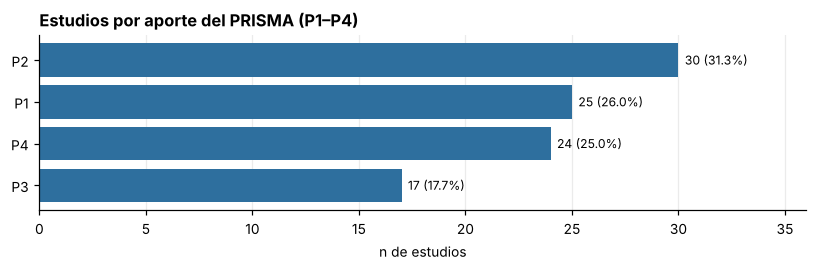

OJO: `plataforma` = editorial/plataforma de origen del artículo, NO las bases de búsqueda (el PICO declara Scopus, Web of Science y SciELO).


,n,% de 96,% de reportados
plataforma,,,
ScienceDirect,47,49.0,49.0
MDPI,19,19.8,19.8
Otra,12,12.5,12.5
Springer Nature,8,8.3,8.3
Wiley,3,3.1,3.1
Frontiers,3,3.1,3.1
PubMed Central,2,2.1,2.1
SciELO,2,2.1,2.1


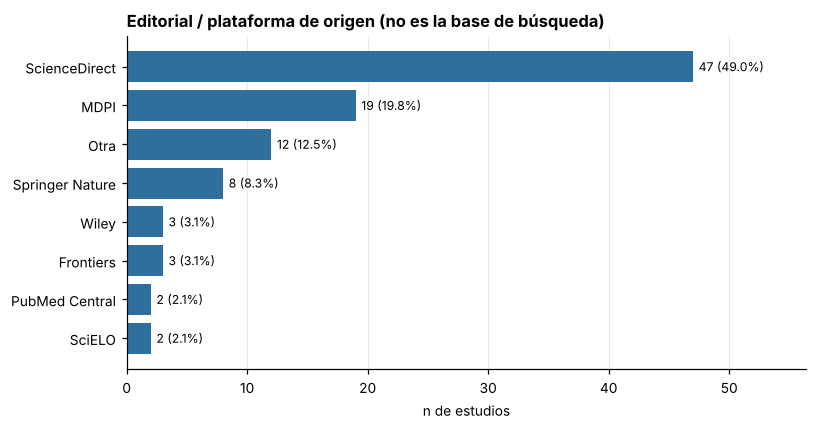

,n,%
anio,,
2021,20,20.8
2022,14,14.6
2023,23,24.0
2024,17,17.7
2025,16,16.7
2026,6,6.3


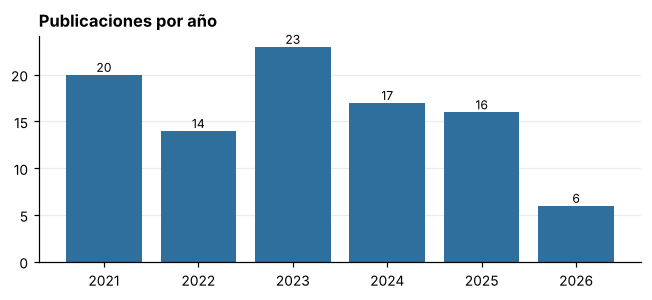

2026 está incompleto (búsqueda realizada el 11–12/10/2026). El periodo 2021–2026 no figura en el PICO: documentarlo en el protocolo.


In [ ]:
t_int = freq('integrante','Estudios por aporte del PRISMA (P1–P4)', key='A_integrante')
print('OJO: `plataforma` = editorial/plataforma de origen del artículo, NO las bases de búsqueda (el PICO declara Scopus, Web of Science y SciELO).')
t_plat = freq('plataforma','Editorial / plataforma de origen (no es la base de búsqueda)', key='A_plataforma')
t_anio = df.anio.value_counts().sort_index().rename('n').to_frame(); t_anio['%'] = r0(t_anio.n/N*100, 1); display(t_anio)
fig, ax = plt.subplots(figsize=(6,2.8)); ax.bar(t_anio.index.astype(str), t_anio.n, color=AZUL)
for i,n in enumerate(t_anio.n): ax.text(i, n+.3, n, ha='center', fontsize=8)
ax.set_title('Publicaciones por año', loc='left', fontweight='bold'); ax.grid(axis='x', alpha=0); plt.tight_layout(); plt.show()
print('2026 está incompleto (búsqueda realizada el 11–12/10/2026). El periodo 2021–2026 no figura en el PICO: documentarlo en el protocolo.')
TABLAS['A_anio'] = t_anio

### A.1 Completitud de la extracción (NR por variable y aporte)
`NR` = el estudio debía reportar el dato y no lo hace (o aún no se extrajo). Un NR alto **limita lo que se puede concluir**, por eso se muestra antes de los resultados.

integrante,P1,P2,P3,P4,Total
calidad_global,100,100,100,100,100
tec_validacion,64,80,100,17,64
prop_validacion,68,80,100,8,63
factor_principal,100,43,88,0,55
rango_valor,32,80,82,29,55
valor_metrica,20,80,82,8,47
metrica,20,80,82,8,47
asociacion,100,0,0,21,31
factores,100,0,0,8,28
motores_datos,24,53,6,0,24


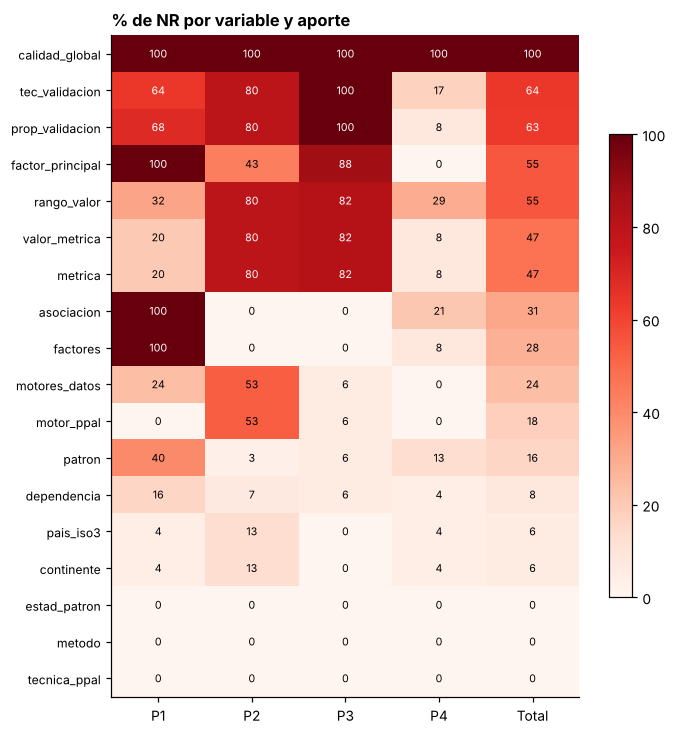

Completitud por estudio (0–1): mediana = 0.58 | media = 0.69


,mean,min,max
integrante,,,
P1,0.56,0.33,0.75
P2,0.64,0.33,1.00
P3,0.61,0.50,0.75
P4,0.93,0.58,1.00


In [ ]:
VARS = ['pais_iso3','continente','tecnica_ppal','metodo','motor_ppal','motores_datos','estad_patron','patron','dependencia',
        'factores','factor_principal','asociacion','tec_validacion','prop_validacion','metrica','valor_metrica','rango_valor','calidad_global']
nr = pd.DataFrame({v: (df.groupby('integrante')[v].apply(lambda s: (s.fillna('NR').astype(str).str.strip()=='NR').mean()*100)) for v in VARS}).T.apply(r0)
nr['Total'] = [ (df[v].fillna('NR').astype(str).str.strip()=='NR').mean()*100 for v in VARS ]; nr['Total'] = r0(nr.Total)
nr = nr.sort_values('Total', ascending=False)
display(nr.style.background_gradient(cmap='Reds', vmin=0, vmax=100).format('{:.0f}'))
fig, ax = plt.subplots(figsize=(6.5, 0.32*len(nr)+1)); im = ax.imshow(nr.values, cmap='Reds', vmin=0, vmax=100, aspect='auto'); ax.grid(False)
ax.set_xticks(range(nr.shape[1])); ax.set_xticklabels(nr.columns); ax.set_yticks(range(nr.shape[0])); ax.set_yticklabels(nr.index, fontsize=8)
for i in range(nr.shape[0]):
    for j in range(nr.shape[1]): ax.text(j,i,int(nr.values[i,j]),ha='center',va='center',fontsize=7,color='white' if nr.values[i,j]>55 else 'black')
ax.set_title('% de NR por variable y aporte', loc='left', fontweight='bold'); plt.colorbar(im, shrink=.7); plt.tight_layout(); plt.show()
TABLAS['A_NR_por_variable'] = nr

# Índice de completitud por estudio (proporción de campos clave con dato, es decir, ≠ NR)
CLAVE = ['tecnica_ppal','motor_ppal','estad_patron','patron','dependencia','factores','factor_principal','asociacion','tec_validacion','prop_validacion','metrica','valor_metrica']
df['completitud'] = 1 - df[CLAVE].apply(lambda c: c.fillna('NR').astype(str).str.strip()=='NR').mean(axis=1)
print('Completitud por estudio (0–1): mediana =', df.completitud.median().round(2), '| media =', df.completitud.mean().round(2))
display(df.groupby('integrante').completitud.agg(['mean','min','max']).round(2))

## P · Población — ¿qué fenómeno forestal y dónde?
`fenomeno`, `continente`, `pais_iso3`/`pais`, `peru`, `area_estudio`.

,n,% de 96,% de reportados
fenomeno,,,
Deforestación y degradación,30,31.3,31.3
Incendios forestales,25,26.0,26.0
Distribución de árboles,24,25.0,25.0
Cambio de cobertura,17,17.7,17.7


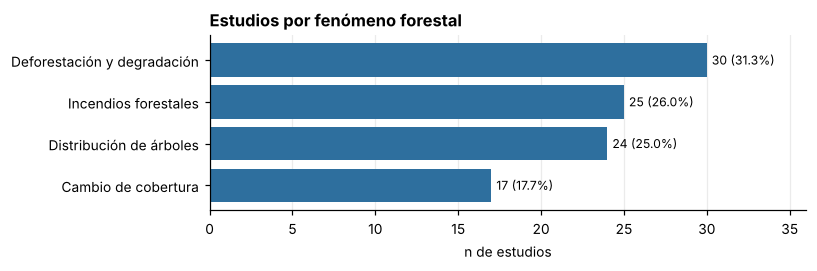

,n,% de 96,% de reportados
continente,,,
Asia,43,44.8,47.8
América del Sur,25,26.0,27.8
América del Norte y Central,7,7.3,7.8
Varios,6,6.3,6.7
NR,6,6.3,NaN
Europa,4,4.2,4.4
África,4,4.2,4.4
Oceanía,1,1.0,1.1


NR = 6 de 96 (6 %). Reportados = 90.


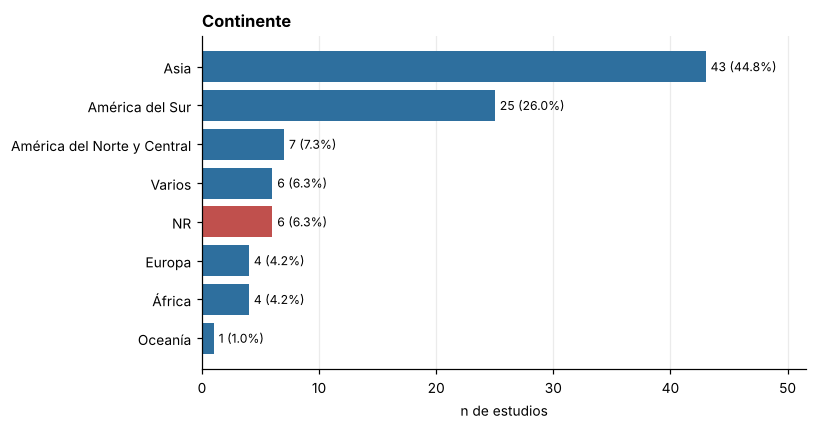

,n,% de 96,% de reportados
pais_iso3,,,
CHN,20,20.8,22.2
PER,11,11.5,12.2
BRA,8,8.3,8.9
IND,8,8.3,8.9
MULTI,6,6.3,6.7
NR,6,6.3,NaN
MEX,4,4.2,4.4
PAK,3,3.1,3.3
CAN,3,3.1,3.3


NR = 6 de 96 (6 %). Reportados = 90.


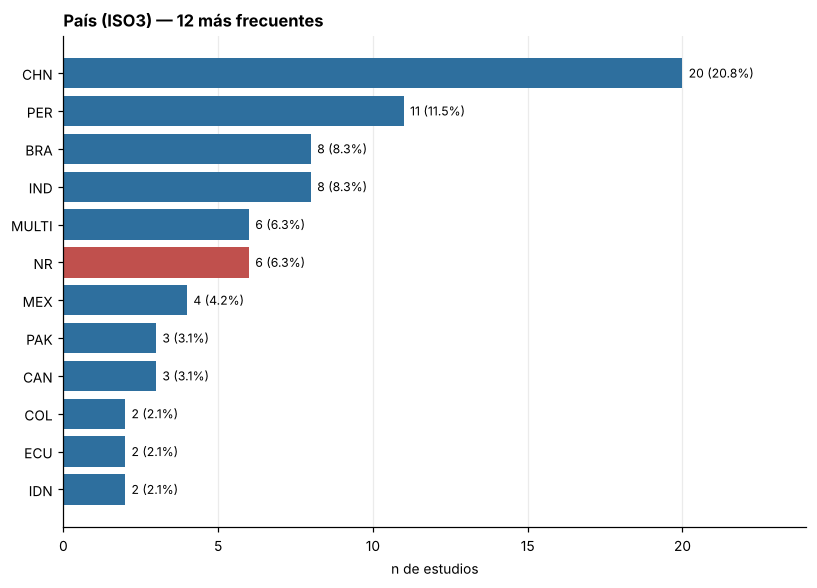

,n,% de 96,% de reportados
peru,,,
No,79,82.3,87.8
Sí,11,11.5,12.2
NR,6,6.3,NaN


NR = 6 de 96 (6 %). Reportados = 90.


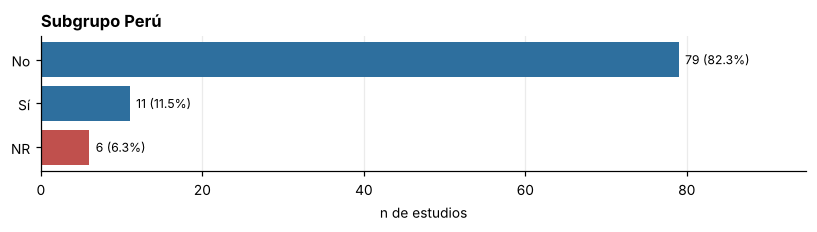

In [ ]:
t_fen = freq('fenomeno','Estudios por fenómeno forestal', key='P_fenomeno')
t_cont = freq('continente','Continente', key='P_continente')
t_pais = freq('pais_iso3','País (ISO3) — 12 más frecuentes', top=12, key='P_pais')
t_peru = freq('peru','Subgrupo Perú', key='P_peru')

**Continente × fenómeno**

fenomeno,Cambio de cobertura,Deforestación y degradación,Distribución de árboles,Incendios forestales,Total
continente,,,,,
América del Norte y Central,2,0,2,3,7
América del Sur,7,13,4,1,25
Asia,6,6,13,18,43
Europa,1,0,2,1,4
NR,0,4,1,1,6
Oceanía,0,0,0,1,1
Varios,0,4,2,0,6
África,1,3,0,0,4
Total,17,30,24,25,96


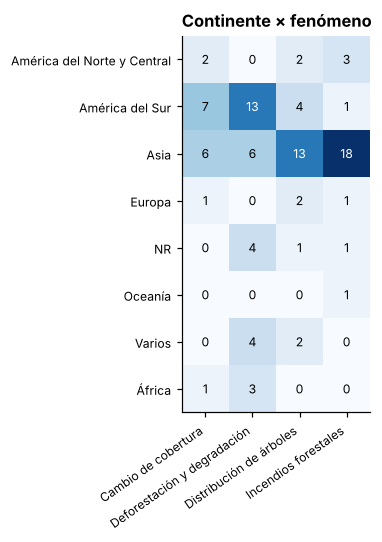

In [ ]:
display(Markdown('**Continente × fenómeno**')); _ = cruz('continente','fenomeno','Continente × fenómeno', key='P_cont_x_fen')

In [ ]:
# Subgrupo Perú: lista y comparación descriptiva con el resto (excluye peru = NR, que son estudios sin país identificado)
per = df[df.peru=='Sí']; res_ = df[df.peru=='No']
print(f'Perú n={len(per)} | Resto n={len(res_)} | NR (sin país) n={(df.peru=="NR").sum()}')
display(per[['id_estudio','integrante','autor','anio','fenomeno','tecnica_ppal','motor_ppal','tipo_problema']])
def comp(col):
    a = per[col].value_counts(normalize=True).mul(100).apply(r0); b = res_[col].value_counts(normalize=True).mul(100).apply(r0)
    return pd.DataFrame({f'Perú (n={len(per)}) %':a, f'Resto (n={len(res_)}) %':b}).fillna(0).astype(int).sort_values(f'Perú (n={len(per)}) %', ascending=False)
for c in ['fenomeno','tecnica_ppal','tipo_problema','motor_ppal']:
    display(Markdown(f'**{c}** — Perú vs. resto')); t = comp(c); display(t); TABLAS[f'P_peru_vs_resto_{c}'] = t
# Brecha para el research gap: técnicas núcleo del PICO en Perú
n_clas = int((per.tecnica_ppal=='Clasificación y detección de cambios').sum())
n_pp   = int((per.tecnica_ppal=='Patrones de puntos').sum()); n_ac = int((per.tecnica_ppal=='Autocorrelación espacial').sum())
print(f'Perú: {n_clas} de {len(per)} estudios usan clasificación/detección de cambios; patrones de puntos = {n_pp}, autocorrelación espacial = {n_ac} (técnica principal).')

Perú n=11 | Resto n=79 | NR (sin país) n=6


,id_estudio,integrante,autor,anio,fenomeno,tecnica_ppal,motor_ppal,tipo_problema
28,E029,P2,Matthew S. Marcus,2024,Deforestación y degradación,Clasificación y detección de cambios,Landsat,Clasificación
29,E030,P2,Gianmarco Goycochea Casas,2023,Deforestación y degradación,Machine learning,NR,Clasificación
30,E031,P2,"Saka, Umut Mete",2024,Deforestación y degradación,Clasificación y detección de cambios,NR,Clasificación
46,E047,P2,"Yang, Wanting",2025,Deforestación y degradación,Machine learning,Otra,Clasificación
48,E049,P2,"Cotrina Sánchez, Alexander",2021,Deforestación y degradación,Otra,NR,Clasificación
54,E055,P3,Manrique,2025,Cambio de cobertura,Regresión espacial,NR,Regresión
55,E056,P3,Aoife Bennett,2023,Cambio de cobertura,Clasificación y detección de cambios,Otra,Clasificación
56,E057,P3,Nilton B. Rojas-Briceño,2025,Cambio de cobertura,Clasificación y detección de cambios,Otra,Clasificación
65,E067,P3,Dante Leonardo Zumaeta Lozano,2021,Cambio de cobertura,Clasificación y detección de cambios,Landsat,Clasificación
69,E071,P3,Frank Alexander La Torre Auccasi,2024,Cambio de cobertura,Clasificación y detección de cambios,Landsat,Clasificación


**fenomeno** — Perú vs. resto

,Perú (n=11) %,Resto (n=79) %
fenomeno,,
Cambio de cobertura,55,14
Deforestación y degradación,45,27
Distribución de árboles,0,29
Incendios forestales,0,30


**tecnica_ppal** — Perú vs. resto

...

**tipo_problema** — Perú vs. resto

,Perú (n=11) %,Resto (n=79) %
tipo_problema,,
Clasificación,91,49
Regresión,9,14
Descriptivo,0,37


**motor_ppal** — Perú vs. resto

,Perú (n=11) %,Resto (n=79) %
motor_ppal,,
Landsat,36,13
NR,36,14
Otra,27,22
Estaciones,0,3
Inventario / campo,0,29
Hansen GFC,0,4
MODIS,0,6
Sentinel-2,0,10


Perú: 7 de 11 estudios usan clasificación/detección de cambios; patrones de puntos = 0, autocorrelación espacial = 0 (técnica principal).


In [ ]:
# Respuesta P
tf, tc, tp = t_fen, t_cont, t_pais
tp_ok = tp[~tp.index.isin(['NR','MULTI'])]
R['P'] = (f"Los {N} estudios se reparten así: " + ', '.join(f"{k} ({v})" for k,v in tf.n.items()) + ". "
          f"El continente más estudiado es {tc.index[0]} ({tc.n.iloc[0]}, {pc(tc['% de reportados'].iloc[0])} % de los reportados), seguido de {tc.index[1]} ({tc.n.iloc[1]}); "
          f"el país más frecuente es {tp_ok.index[0]} ({tp_ok.n.iloc[0]}) y luego {tp_ok.index[1]} ({tp_ok.n.iloc[1]}). El subgrupo Perú reúne {len(per)} estudios ({pc(len(per)/N*100)} %): {n_clas} usan clasificación y detección de cambios y ninguno usa patrones de puntos ni autocorrelación espacial como técnica principal ({n_pp} y {n_ac}), lo que sustenta el vacío de investigación (research gap) en el país.")
display(Markdown('> **Respuesta P.** ' + R['P']))

> **Respuesta P.** Los 96 estudios se reparten así: Deforestación y degradación (30), Incendios forestales (25), Distribución de árboles (24), Cambio de cobertura (17). El continente más estudiado es Asia (43, 48 % de los reportados), seguido de América del Sur (25); el país más frecuente es CHN (20) y luego PER (11). El subgrupo Perú reúne 11 estudios (11 %): 7 usan clasificación y detección de cambios y ninguno usa patrones de puntos ni autocorrelación espacial como técnica principal (0 y 0), lo que sustenta el vacío de investigación (research gap) en el país.

## I · Intervención — ¿qué técnica geoespacial y qué motor de datos?
### I.1 Técnica y método

,n,% de 96,% de reportados
tecnica_ppal,,,
Clasificación y detección de cambios,25,26.0,26.0
Patrones de puntos,24,25.0,25.0
Machine learning,15,15.6,15.6
Autocorrelación espacial,14,14.6,14.6
SIG multicriterio,6,6.3,6.3
Regresión espacial,5,5.2,5.2
Interpolación,4,4.2,4.2
Otra,3,3.1,3.1


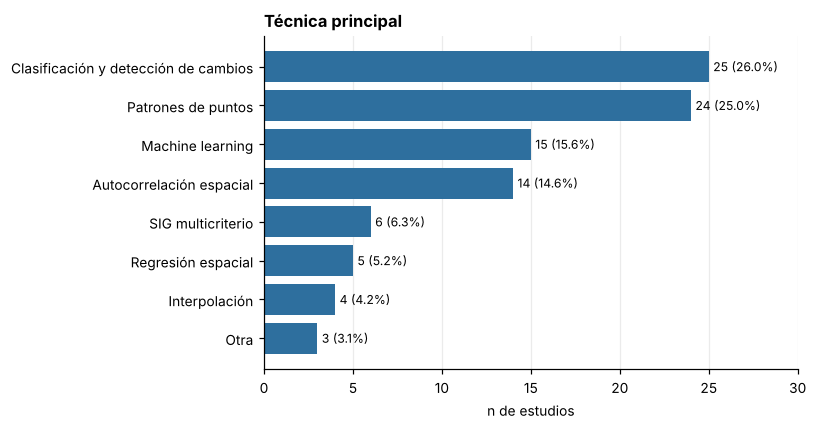

**Método específico** (tabla N1) — 15 más frecuentes

,n,% de 96,% de reportados
metodo,,,
Análisis multitemporal de cobertura,13,13.5,13.5
Correlación de pares g(r),10,10.4,10.4
Ripley K,7,7.3,7.3
Getis-Ord Gi*,7,7.3,7.3
Random Forest,6,6.3,6.3
Red neuronal,5,5.2,5.2
Clasificación supervisada,5,5.2,5.2
"Rezago / error espacial (SAR, SEM)",4,4.2,4.2
Moran global,4,4.2,4.2


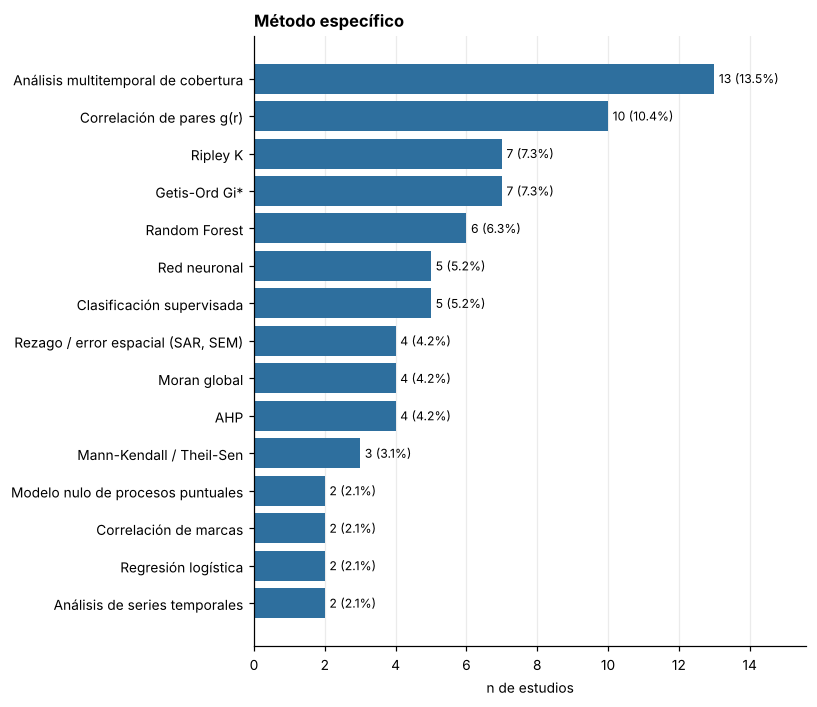

In [ ]:
t_tec = freq('tecnica_ppal','Técnica principal', key='I_tecnica_ppal')
display(Markdown('**Método específico** (tabla N1) — 15 más frecuentes')); t_met = freq('metodo','Método específico', top=15, key='I_metodo')

### I.1b Técnicas dentro y fuera de la intervención del PICO
El PICO define la intervención como **patrones de puntos, autocorrelación espacial, interpolación y SIG**. Las demás técnicas del corpus (clasificación y detección de cambios, machine learning, regresión espacial, otra) **no están en el PICO**: hay que **ampliar la definición de intervención o justificar su inclusión**. Además se verifica si el *kernel* que menciona el PICO aparece entre los métodos.

,n,% de 96,% de reportados
grupo_pico,,,
"Núcleo PICO (puntos, autocorrelación, interpolación, SIG)",48,50.0,50.0
Fuera del PICO (ampliación),48,50.0,50.0


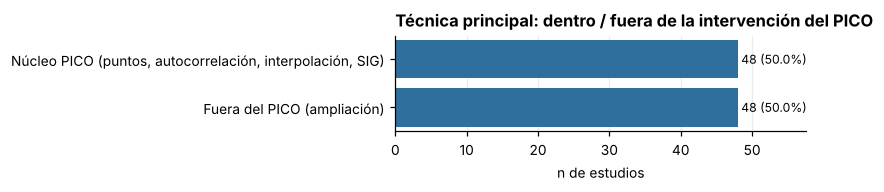

**Detalle de las técnicas fuera del PICO**

,n
tecnica_ppal,
Clasificación y detección de cambios,25
Machine learning,15
Regresión espacial,5
Otra,3


**Grupo PICO × fenómeno**

fenomeno,Cambio de cobertura,Deforestación y degradación,Distribución de árboles,Incendios forestales,Total
grupo_pico,,,,,
Fuera del PICO (ampliación),16,23,3,6,48
"Núcleo PICO (puntos, autocorrelación, interpolación, SIG)",1,7,21,19,48
Total,17,30,24,25,96


«Kernel» entre los 15 métodos más frecuentes: NO | estudios con método kernel/KDE: 1. El PICO lo menciona: revisar si debe quitarse del PICO o extraerse.


In [ ]:
NUCLEO_PICO = ['Patrones de puntos','Autocorrelación espacial','Interpolación','SIG multicriterio']
df['grupo_pico'] = np.where(df.tecnica_ppal.isin(NUCLEO_PICO), 'Núcleo PICO (puntos, autocorrelación, interpolación, SIG)', 'Fuera del PICO (ampliación)')
t_gp = freq('grupo_pico','Técnica principal: dentro / fuera de la intervención del PICO', key='I_grupo_pico')
display(Markdown('**Detalle de las técnicas fuera del PICO**'))
t_fuera = df[df.grupo_pico.str.startswith('Fuera')].tecnica_ppal.value_counts().rename('n').to_frame(); display(t_fuera); TABLAS['I_fuera_PICO'] = t_fuera
display(Markdown('**Grupo PICO × fenómeno**')); _ = cruz('grupo_pico','fenomeno','Grupo PICO × fenómeno', key='I_grupo_x_fen', plot=False)
kern = df.metodo.fillna('').str.contains('kernel|KDE', case=False, regex=True)
mets15 = df.metodo.fillna('NR').value_counts().head(15).index
print(f'«Kernel» entre los 15 métodos más frecuentes: {"sí" if kern.any() and any(df.loc[kern,"metodo"].isin(mets15)) else "NO"} | estudios con método kernel/KDE: {int(kern.sum())}. El PICO lo menciona: revisar si debe quitarse del PICO o extraerse.')

**Método específico dentro de cada técnica principal**

,tecnica_ppal,metodo,n
0,Autocorrelación espacial,Getis-Ord Gi*,6
1,Autocorrelación espacial,Moran global,4
2,Autocorrelación espacial,Análisis multitemporal de cobertura,1
3,Autocorrelación espacial,Mann-Kendall / Theil-Sen,1
4,Clasificación y detección de cambios,Análisis multitemporal de cobertura,12
5,Clasificación y detección de cambios,Clasificación supervisada,5
6,Clasificación y detección de cambios,Análisis de series temporales,2
7,Clasificación y detección de cambios,CCDC,2
8,Interpolación,Interpolación (método no especificado),2
9,Interpolación,Kriging ordinario,2


**Técnicas secundarias** (multirrespuesta)

,n,% de 96,% de reportados
op,,,
Ninguna,75,78.1,78.1
Autocorrelación espacial,8,8.3,8.3
Clasificación y detección de cambios,6,6.3,6.3
Machine learning,4,4.2,4.2
Patrones de puntos,3,3.1,3.1
SIG multicriterio,3,3.1,3.1


Estudios con dato: 96 | NR: 0. Un estudio puede aparecer en varias filas.


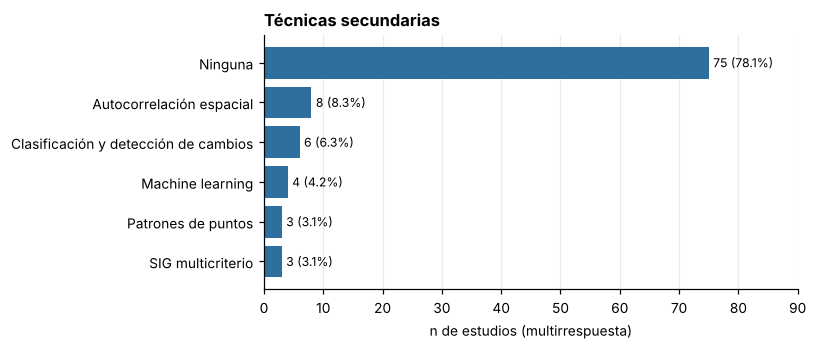

Estudios que combinan ≥2 técnicas: 21 de 96 (22 %)


In [ ]:
display(Markdown('**Método específico dentro de cada técnica principal**'))
mt = df.groupby(['tecnica_ppal','metodo']).size().rename('n').reset_index().sort_values(['tecnica_ppal','n'], ascending=[True,False])
display(mt.groupby('tecnica_ppal').head(4).reset_index(drop=True)); TABLAS['I_metodo_por_tecnica'] = mt
display(Markdown('**Técnicas secundarias** (multirrespuesta)')); t_sec = multi('tecnicas_secundarias','Técnicas secundarias', key='I_secundarias')
df['n_tec'] = 1 + df.tecnicas_secundarias.fillna('Ninguna').apply(lambda s: 0 if s.strip()=='Ninguna' else len(s.split(';')))
print(f'Estudios que combinan ≥2 técnicas: {(df.n_tec>1).sum()} de {N} ({pc((df.n_tec>1).mean()*100)} %)')

### I.2 Tipo de problema y técnica resumida

,n,% de 96,% de reportados
tipo_problema,,,
Clasificación,51,53.1,53.1
Descriptivo,32,33.3,33.3
Regresión,13,13.5,13.5


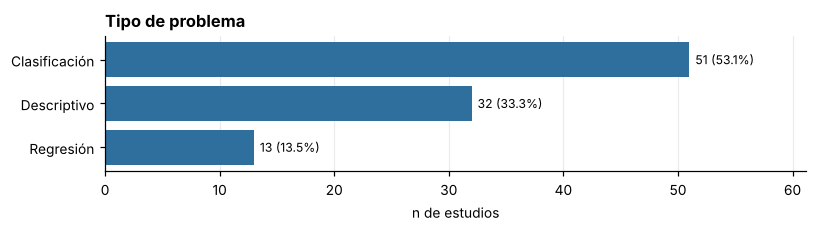

,n,% de 96,% de reportados
tecnica_resumen,,,
Clasificación y detección de cambios – Clasificación,24,25.0,25.0
Patrones de puntos – Descriptivo,21,21.9,21.9
Machine learning – Clasificación,14,14.6,14.6
Autocorrelación espacial – Descriptivo,10,10.4,10.4
SIG multicriterio – Clasificación,6,6.3,6.3
Regresión espacial – Regresión,5,5.2,5.2
Autocorrelación espacial – Clasificación,3,3.1,3.1
Interpolación – Regresión,3,3.1,3.1
Patrones de puntos – Clasificación,2,2.1,2.1


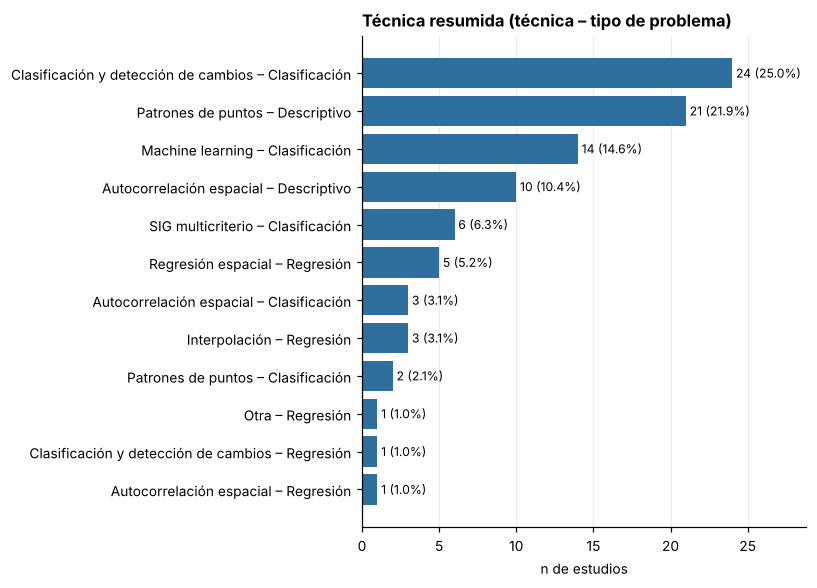

In [ ]:
t_tip = freq('tipo_problema','Tipo de problema', key='I_tipo_problema')
t_res = freq('tecnica_resumen','Técnica resumida (técnica – tipo de problema)', top=12, key='I_tecnica_resumen')

### I.3 Cruces técnica × fenómeno × tipo de problema

**Técnica principal × fenómeno** (conteos y % por fila)

fenomeno,Cambio de cobertura,Deforestación y degradación,Distribución de árboles,Incendios forestales,Total
tecnica_ppal,,,,,
Autocorrelación espacial,1,7,1,5,14
Clasificación y detección de cambios,11,13,0,1,25
Interpolación,0,0,0,4,4
Machine learning,4,7,1,3,15
Otra,0,2,0,1,3
Patrones de puntos,0,0,20,4,24
Regresión espacial,1,1,2,1,5
SIG multicriterio,0,0,0,6,6
Total,17,30,24,25,96


fenomeno,Cambio de cobertura (%),Deforestación y degradación (%),Distribución de árboles (%),Incendios forestales (%)
tecnica_ppal,,,,
Autocorrelación espacial,7.1,50.0,7.1,35.7
Clasificación y detección de cambios,44.0,52.0,0.0,4.0
Interpolación,0.0,0.0,0.0,100.0
Machine learning,26.7,46.7,6.7,20.0
Otra,0.0,66.7,0.0,33.3
Patrones de puntos,0.0,0.0,83.3,16.7
Regresión espacial,20.0,20.0,40.0,20.0
SIG multicriterio,0.0,0.0,0.0,100.0


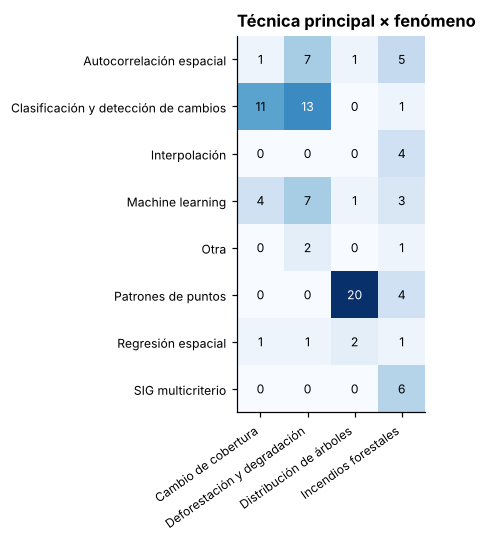

In [ ]:
display(Markdown('**Técnica principal × fenómeno** (conteos y % por fila)'))
t6 = cruz('tecnica_ppal','fenomeno','Técnica principal × fenómeno', key='I_tec_x_fen', pct_fila=True)

**Técnica principal × tipo de problema**

tipo_problema,Clasificación,Descriptivo,Regresión,Total
tecnica_ppal,,,,
Autocorrelación espacial,3,10,1,14
Clasificación y detección de cambios,24,0,1,25
Interpolación,1,0,3,4
Machine learning,14,0,1,15
Otra,1,1,1,3
Patrones de puntos,2,21,1,24
Regresión espacial,0,0,5,5
SIG multicriterio,6,0,0,6
Total,51,32,13,96


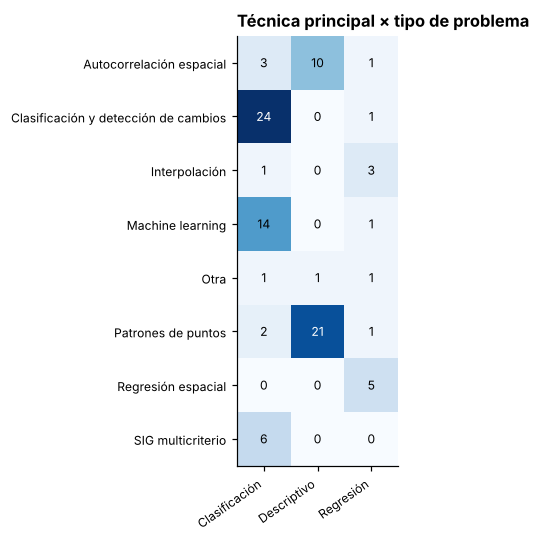

**Fenómeno × tipo de problema** (% por fenómeno)

tipo_problema,Clasificación,Descriptivo,Regresión
fenomeno,,,
Cambio de cobertura,88.0,0.0,12.0
Deforestación y degradación,67.0,20.0,13.0
Distribución de árboles,8.0,83.0,8.0
Incendios forestales,56.0,24.0,20.0


In [ ]:
display(Markdown('**Técnica principal × tipo de problema**')); t7 = cruz('tecnica_ppal','tipo_problema','Técnica principal × tipo de problema', key='I_tec_x_tipo')
display(Markdown('**Fenómeno × tipo de problema** (% por fenómeno)'))
display((pd.crosstab(df.fenomeno, df.tipo_problema, normalize='index')*100).round(0))

tecnica_ppal,Autocorrelación espacial,Clasificación y detección de cambios,Interpolación,Machine learning,Otra,Patrones de puntos,Regresión espacial,SIG multicriterio
anio,,,,,,,,
2021,1,10,0,1,1,5,2,0
2022,1,3,1,2,0,5,0,2
2023,4,5,1,5,1,5,0,2
2024,2,4,2,3,1,3,1,1
2025,4,2,0,4,0,4,2,0
2026,2,1,0,0,0,2,0,1


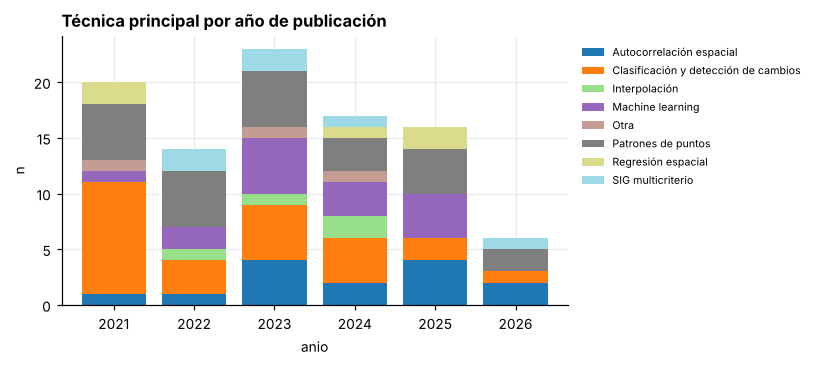

In [ ]:
# Tendencia temporal de la técnica principal (por año de publicación)
m = pd.crosstab(df.anio, df.tecnica_ppal); display(m)
m.plot(kind='bar', stacked=True, figsize=(7.5,3.4), colormap='tab20', width=.8); plt.xticks(rotation=0)
plt.legend(bbox_to_anchor=(1.01,1), loc='upper left', frameon=False, fontsize=7); plt.title('Técnica principal por año de publicación', loc='left', fontweight='bold'); plt.ylabel('n'); plt.tight_layout(); plt.show()
TABLAS['I_tec_por_anio'] = m

### I.4 Motor de datos
`motor_ppal` (uno) y `motores_datos` (varios). Para el análisis, `Otra (Planet)`, `Otra (LiDAR…)`, etc. se agrupan en **Otra**; el detalle queda en la tabla de abajo.

,n,% de 96,% de reportados
motor_ppal_n,,,
Inventario / campo,24,25.0,30.4
Otra,21,21.9,26.6
NR,17,17.7,NaN
Landsat,15,15.6,19.0
Sentinel-2,8,8.3,10.1
MODIS,5,5.2,6.3
Hansen GFC,4,4.2,5.1
Estaciones,2,2.1,2.5


NR = 17 de 96 (18 %). Reportados = 79.


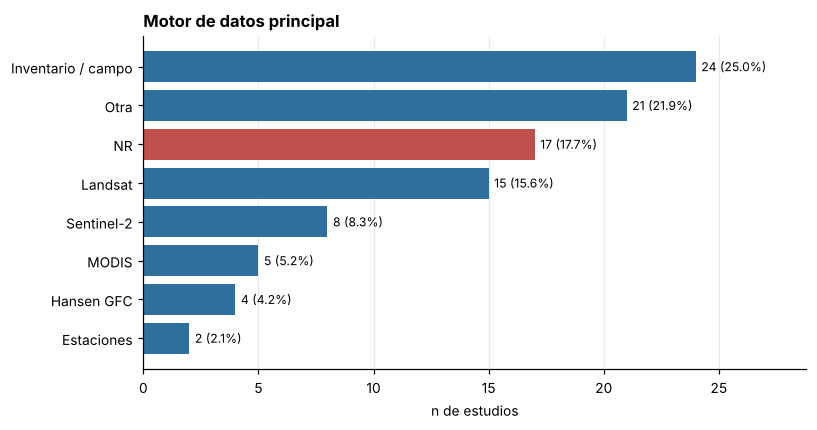

**Motores usados** (multirrespuesta)

,n,% de 96,% de reportados
op,,,
Otra,25,26.0,34.2
Inventario / campo,24,25.0,32.9
Landsat,18,18.8,24.7
Sentinel-2,8,8.3,11.0
MODIS,7,7.3,9.6
Hansen GFC,5,5.2,6.8
Estaciones,2,2.1,2.7
VIIRS / FIRMS,2,2.1,2.7
DEM,1,1.0,1.4


Estudios con dato: 73 | NR: 23. Un estudio puede aparecer en varias filas.


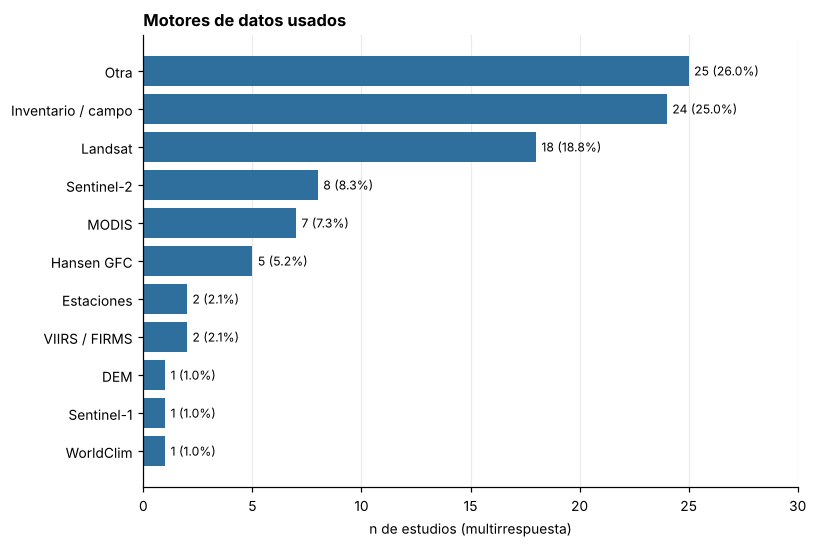

Motores por estudio (solo estudios con dato):


,count,mean,std,min,25%,50%,75%,max
n_motores,73.0,1.29,0.56,1.0,1.0,1.0,1.0,4.0


**Detalle de «Otra»** (fuentes que no están en la lista cerrada)

,n
motores_datos,
Planet,2
Datos ambientales multifuente,2
Registros de incendios,2
imagen GF-2,1
LiDAR NCALM,1
NASA GFCC,1
LiDAR aéreo y terrestre,1
Sentinel,1
GEOBOSQUES,1


In [ ]:
df['motor_ppal_n'] = df.motor_ppal.fillna('NR').astype(str).str.replace(r'^(Otra)\s*\(.*\)$', r'\1', regex=True)
t_mot = freq('motor_ppal_n','Motor de datos principal', key='I_motor_ppal')
display(Markdown('**Motores usados** (multirrespuesta)')); t_mots = multi('motores_datos','Motores de datos usados', key='I_motores_datos')
df['n_motores'] = df.motores_datos.fillna('').apply(lambda s: 0 if s.strip() in ('','NR') else len([x for x in s.split(';') if x.strip()]))
print('Motores por estudio (solo estudios con dato):'); display(df.loc[df.n_motores>0,'n_motores'].describe().round(2).to_frame('n_motores').T)
det = df.motores_datos.dropna().str.split(';').explode().str.strip(); det = det[det.str.startswith('Otra (')].str.replace(r'^Otra \((.*)\)$', r'\1', regex=True).value_counts()
display(Markdown('**Detalle de «Otra»** (fuentes que no están en la lista cerrada)')); display(det.to_frame('n').head(15))

**Motor principal × fenómeno**

fenomeno,Cambio de cobertura,Deforestación y degradación,Distribución de árboles,Incendios forestales,Total
motor_ppal_n,,,,,
Estaciones,0,0,0,2,2
Hansen GFC,0,4,0,0,4
Inventario / campo,0,0,20,4,24
Landsat,9,5,0,1,15
MODIS,1,0,0,4,5
NR,1,16,0,0,17
Otra,3,2,4,12,21
Sentinel-2,3,3,0,2,8
Total,17,30,24,25,96


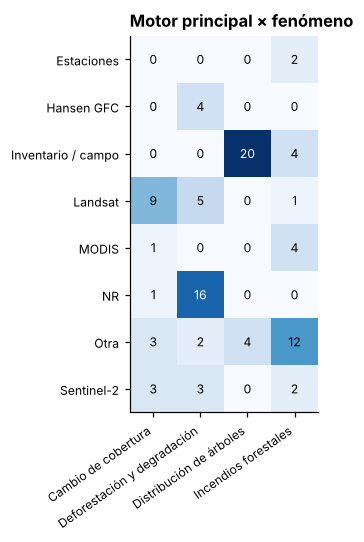

**Motor principal × técnica principal**

tecnica_ppal,Autocorrelación espacial,Clasificación y detección de cambios,Interpolación,Machine learning,Otra,Patrones de puntos,Regresión espacial,SIG multicriterio,Total
motor_ppal_n,,,,,,,,,
Estaciones,0,0,2,0,0,0,0,0,2
Hansen GFC,2,2,0,0,0,0,0,0,4
Inventario / campo,2,0,1,0,0,19,1,1,24
Landsat,0,11,0,3,0,0,1,0,15
MODIS,1,0,1,1,0,1,0,1,5
NR,5,5,0,3,2,0,2,0,17
Otra,4,3,0,4,1,4,1,4,21
Sentinel-2,0,4,0,4,0,0,0,0,8
Total,14,25,4,15,3,24,5,6,96


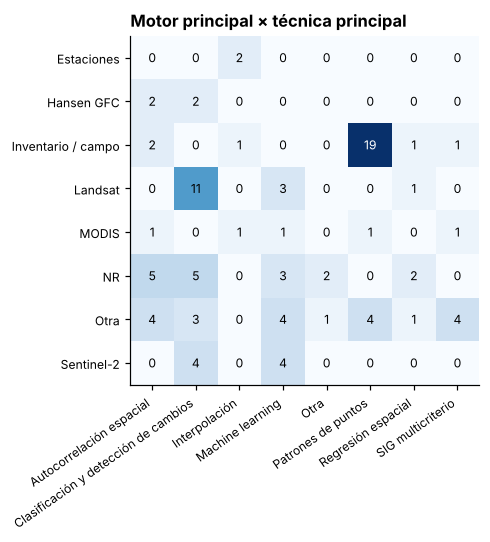

In [ ]:
display(Markdown('**Motor principal × fenómeno**')); t_mxf = cruz('motor_ppal_n','fenomeno','Motor principal × fenómeno', key='I_motor_x_fen')
display(Markdown('**Motor principal × técnica principal**')); t_mxt = cruz('motor_ppal_n','tecnica_ppal','Motor principal × técnica principal', key='I_motor_x_tec')

In [ ]:
tt = t_tec; tm = t_mot
top_tec = lider(tt); top_mot = lider(tm)
sec = (df.tecnicas_secundarias.fillna('Ninguna')!='Ninguna').sum()
n_nuc = int(df.tecnica_ppal.isin(NUCLEO_PICO).sum())
R['I'] = (f"La técnica principal más usada es «{top_tec[0]}» ({top_tec[1]} estudios, {pc(top_tec[2])} %), seguida de {tt.index[1]} ({tt.n.iloc[1]}) y {tt.index[2]} ({tt.n.iloc[2]}). "
          f"{pc((df.tipo_problema=='Clasificación').mean()*100)} % de los estudios son de clasificación y {pc((df.tipo_problema=='Descriptivo').mean()*100)} % solo describen el patrón; la regresión es minoritaria ({pc((df.tipo_problema=='Regresión').mean()*100)} %). "
          f"Solo {sec} estudios ({pc(sec/N*100)} %) combinan una técnica secundaria. Motor principal más frecuente entre los reportados: «{top_mot[0]}» ({top_mot[1]}, {pc(top_mot[2])} %); "
          f"{(df.motor_ppal_n=='NR').sum()} estudios no lo reportan y {(df.motor_ppal_n=='Otra').sum()} usan una fuente fuera de la lista cerrada. Solo {n_nuc} de {N} estudios ({pc(n_nuc/N*100)} %) usan como técnica principal una de las 4 del PICO (patrones de puntos, autocorrelación, interpolación, SIG); los otros {N-n_nuc} son técnicas fuera de la intervención definida (clasificación y detección de cambios, machine learning, regresión espacial, otra), por lo que el PICO debe ampliarse o justificarse. El kernel mencionado en el PICO no aparece entre los 15 métodos más frecuentes.")
display(Markdown('> **Respuesta I.** ' + R['I']))

> **Respuesta I.** La técnica principal más usada es «Clasificación y detección de cambios» (25 estudios, 26 %), seguida de Patrones de puntos (24) y Machine learning (15). 53 % de los estudios son de clasificación y 33 % solo describen el patrón; la regresión es minoritaria (14 %). Solo 21 estudios (22 %) combinan una técnica secundaria. Motor principal más frecuente entre los reportados: «Inventario / campo» (24, 30 %); 17 estudios no lo reportan y 21 usan una fuente fuera de la lista cerrada. Solo 48 de 96 estudios (50 %) usan como técnica principal una de las 4 del PICO (patrones de puntos, autocorrelación, interpolación, SIG); los otros 48 son técnicas fuera de la intervención definida (clasificación y detección de cambios, machine learning, regresión espacial, otra), por lo que el PICO debe ampliarse o justificarse. El kernel mencionado en el PICO no aparece entre los 15 métodos más frecuentes.

## O · Resultados
### O.1 Patrón espacial
`estad_patron`, `patron`, `dependencia`. Regla de la ficha: si el estadístico es **Ninguno**, el patrón es **No evaluado**.

,n,% de 96,% de reportados
estad_patron,,,
Ninguno,60,62.5,62.5
Otro,18,18.8,18.8
Ripley K / L,7,7.3,7.3
LISA,5,5.2,5.2
Moran global,3,3.1,3.1
Getis-Ord Gi*,3,3.1,3.1


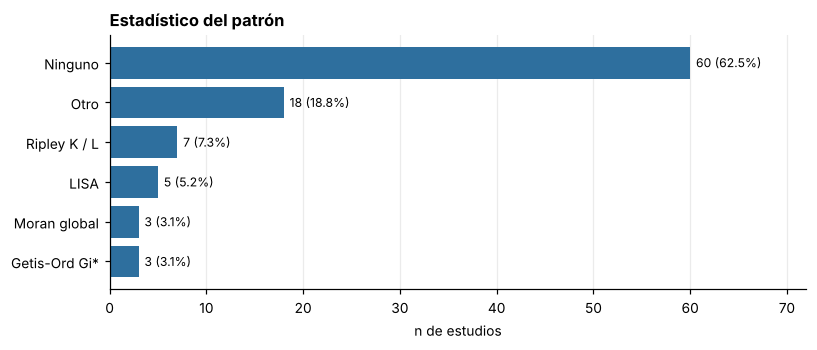

,n,% de 96,% de reportados
patron,,,
No evaluado,63,65.6,77.8
NR,15,15.6,NaN
Mixto (cambia con la escala),9,9.4,11.1
Agrupado,9,9.4,11.1


NR = 15 de 96 (16 %). Reportados = 81.


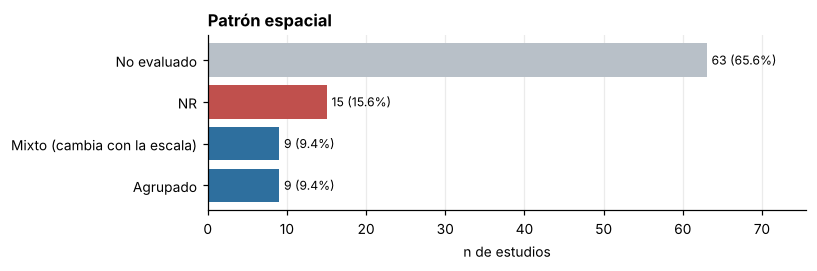

,n,% de 96,% de reportados
dependencia,,,
No evaluada,84,87.5,95.5
NR,8,8.3,NaN
Positiva significativa,4,4.2,4.5


NR = 8 de 96 (8 %). Reportados = 88.


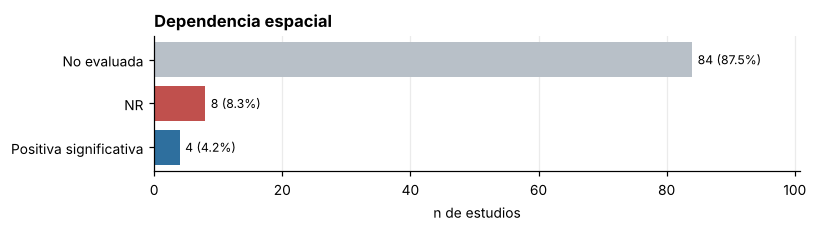

In [ ]:
t_ep = freq('estad_patron','Estadístico del patrón', key='O1_estad_patron')
t_pa = freq('patron','Patrón espacial', key='O1_patron')
t_de = freq('dependencia','Dependencia espacial', key='O1_dependencia')

Estudios que aplicaron un estadístico de patrón: 36 de 96 (38 %)


**Patrón entre quienes evaluaron**

,n,% de 36,% de reportados
patron,,,
NR,15,41.7,NaN
Mixto (cambia con la escala),9,25.0,42.9
Agrupado,9,25.0,42.9
No evaluado,3,8.3,14.3


NR = 15 de 36 (42 %). Reportados = 21.


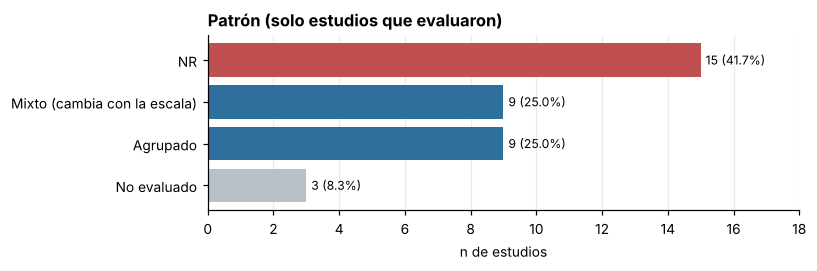

**Estadístico del patrón × patrón** (solo evaluaron)

patron,Agrupado,Mixto (cambia con la escala),NR,No evaluado,Total
estad_patron,,,,,
Getis-Ord Gi*,0,0,3,0,3
LISA,1,0,3,1,5
Moran global,1,0,2,0,3
Otro,5,5,6,2,18
Ripley K / L,2,4,1,0,7
Total,9,9,15,3,36


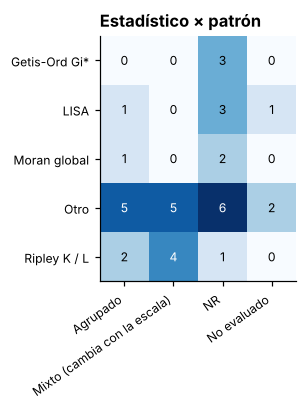

**Técnica principal × patrón** (solo evaluaron)

patron,Agrupado,Mixto (cambia con la escala),NR,No evaluado,Total
tecnica_ppal,,,,,
Autocorrelación espacial,1,0,6,1,8
Machine learning,0,0,1,0,1
Patrones de puntos,7,9,6,2,24
Regresión espacial,1,0,2,0,3
Total,9,9,15,3,36


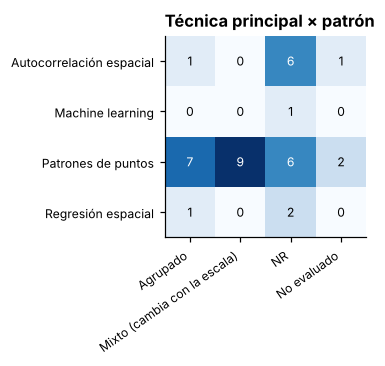

**Fenómeno × patrón** (solo evaluaron)

patron,Agrupado,Mixto (cambia con la escala),NR,No evaluado,Total
fenomeno,,,,,
Cambio de cobertura,0,0,1,0,1
Deforestación y degradación,1,0,1,0,2
Distribución de árboles,8,9,3,3,23
Incendios forestales,0,0,10,0,10
Total,9,9,15,3,36


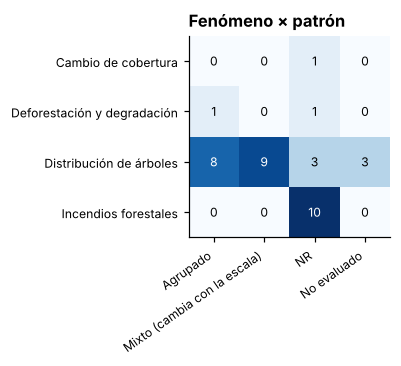

**Patrones esperados por el PICO frente a los extraídos**

,n,En el PICO
patron,,
Agrupado,9,Sí
Aleatorio,0,Sí
Regular / disperso,0,Sí
Mixto (cambia con la escala),9,No (surge de los datos)
No evaluado,3,—
NR,15,—


Zonas de concentración (hot spots) y escala del patrón: el PICO las espera, pero NO existen columnas para ellas en la matriz → no se extrajeron.


**Estadístico de patrón Moran/LISA/Gi\* × dependencia espacial**

dependencia,NR,Positiva significativa,Total
estad_patron,,,
Getis-Ord Gi*,3,0,3
LISA,3,2,5
Moran global,2,1,3
Total,8,3,11


In [ ]:
# Solo estudios que evaluaron patrón (estad_patron ≠ Ninguno). Dentro de ellos, el patrón puede ser NR (se evaluó pero no se extrajo el resultado)
ev = df[df.estad_patron!='Ninguno']
print(f'Estudios que aplicaron un estadístico de patrón: {len(ev)} de {N} ({len(ev)/N*100:.0f} %)')
display(Markdown('**Patrón entre quienes evaluaron**')); t_pa_ev = freq('patron','Patrón (solo estudios que evaluaron)', data=ev, key='O1_patron_evaluados')
display(Markdown('**Estadístico del patrón × patrón** (solo evaluaron)')); _ = cruz('estad_patron','patron','Estadístico × patrón', data=ev, key='O1_estad_x_patron')
display(Markdown('**Técnica principal × patrón** (solo evaluaron)')); _ = cruz('tecnica_ppal','patron','Técnica principal × patrón', data=ev, key='O1_tec_x_patron')
display(Markdown('**Fenómeno × patrón** (solo evaluaron)')); _ = cruz('fenomeno','patron','Fenómeno × patrón', data=ev, key='O1_fen_x_patron')
display(Markdown('**Patrones esperados por el PICO frente a los extraídos**'))
esp = ['Agrupado','Aleatorio','Regular / disperso','Mixto (cambia con la escala)']
t_esp = ev.patron.fillna('NR').value_counts().reindex(esp + ['No evaluado','NR'], fill_value=0).rename('n').to_frame()
t_esp['En el PICO'] = ['Sí','Sí','Sí','No (surge de los datos)','—','—']; display(t_esp); TABLAS['O1_patrones_PICO'] = t_esp
print('Zonas de concentración (hot spots) y escala del patrón: el PICO las espera, pero NO existen columnas para ellas en la matriz → no se extrajeron.')
display(Markdown('**Estadístico de patrón Moran/LISA/Gi\\* × dependencia espacial**'))
_ = cruz('estad_patron','dependencia','Estadístico × dependencia', data=df[df.estad_patron.isin(['Moran global','LISA','Getis-Ord Gi*'])], key='O1_estad_x_dependencia', plot=False)

In [ ]:
vp = ev[~ev.patron.isin(['NR','No evaluado'])]; stat = t_ep[~t_ep.index.isin(['Ninguno','Otro','NR'])]
R['O1'] = (f"Solo {len(ev)} de {N} estudios ({pc(len(ev)/N*100)} %) aplican un estadístico de patrón; entre los estadísticos de la lista, el más usado es «{stat.index[0]}» ({stat.n.iloc[0]}), y {int((df.estad_patron=='Otro').sum())} usan «Otro» (estadísticos fuera de la lista). "
           f"De los {len(ev)}, {int((ev.patron=='NR').sum())} no tienen el patrón extraído (NR). Entre los {len(vp)} con patrón reportado: "
           + ', '.join(f"{k} {v}" for k,v in vp.patron.value_counts().items())
           + f". Los patrones extraídos son solo Agrupado y Mixto; no hay ninguno Aleatorio ni Regular/disperso, y las zonas de concentración y la escala del patrón no se extrajeron. "
           f"De {int(usan_stat.sum())} estudios que usan Moran, LISA o Gi*, solo {int((usan_stat & ~df.dependencia.fillna('NR').isin(['NR','No evaluada'])).sum())} reportan la dependencia espacial ({int((usan_stat & (df.dependencia.fillna('NR')=='NR')).sum())} en NR); ninguno reporta negativa ni no significativa.")
display(Markdown('> **Respuesta O.1.** ' + R['O1']))

> **Respuesta O.1.** Solo 36 de 96 estudios (38 %) aplican un estadístico de patrón; entre los estadísticos de la lista, el más usado es «Ripley K / L» (7), y 18 usan «Otro» (estadísticos fuera de la lista). De los 36, 15 no tienen el patrón extraído (NR). Entre los 18 con patrón reportado: Mixto (cambia con la escala) 9, Agrupado 9. Los patrones extraídos son solo Agrupado y Mixto; no hay ninguno Aleatorio ni Regular/disperso, y las zonas de concentración y la escala del patrón no se extrajeron. De 11 estudios que usan Moran, LISA o Gi*, solo 3 reportan la dependencia espacial (8 en NR); ninguno reporta negativa ni no significativa.

### O.2 Factores ambientales asociados
`factores` (grupos, multirrespuesta), `factor_principal` y `asociacion`. Los porcentajes de grupos se calculan **sobre los estudios que analizan factores y lo reportan** (excluye *No analiza factores* y NR).

,n,% de 96,% de reportados
factores,,,
No analiza factores,34,35.4,49.3
NR,27,28.1,NaN
Antrópicos,12,12.5,17.4
Cobertura / vegetación,9,9.4,13.0
Hidroclimáticos; Cobertura / vegetación,3,3.1,4.3
Topográficos; Edáficos,2,2.1,2.9
Topográficos; Antrópicos,2,2.1,2.9
Cobertura / vegetación; Antrópicos,2,2.1,2.9


NR = 27 de 96 (28 %). Reportados = 69.


**Analiza factores ambientales**

,n,% de 96,% de reportados
analiza_fact,,,
Sí analiza,35,36.5,50.7
No analiza,34,35.4,49.3
NR,27,28.1,NaN


NR = 27 de 96 (28 %). Reportados = 69.


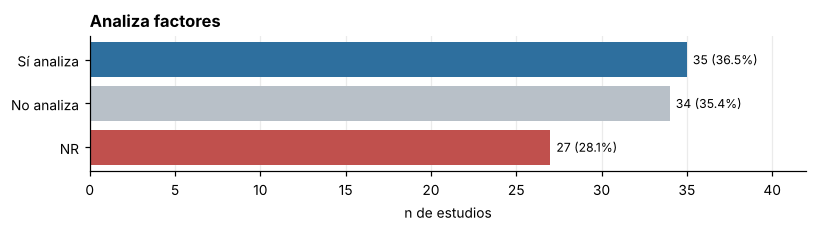

**Grupos de factores** — base: 35 estudios que analizan factores

,n,% de 35,% de reportados
op,,,
Antrópicos,18,51.4,51.4
Cobertura / vegetación,14,40.0,40.0
Topográficos,7,20.0,20.0
Hidroclimáticos,6,17.1,17.1
Edáficos,3,8.6,8.6


Estudios con dato: 35 | NR: 0. Un estudio puede aparecer en varias filas.


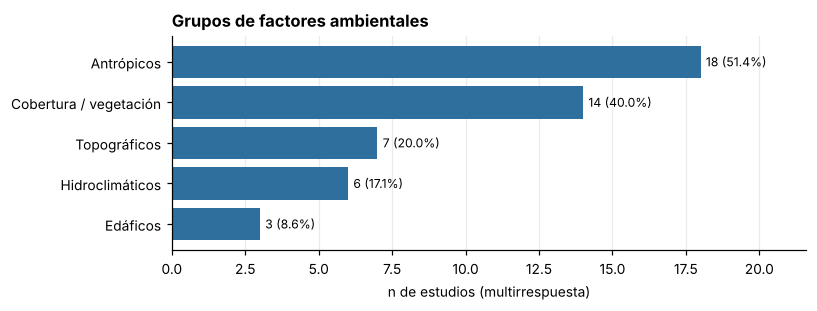

**Grupos de factores frente a los que menciona el PICO** (hidroclimáticos, topográficos y de cobertura)

,n,% de 35,% de reportados,En el PICO
op,,,,
Antrópicos,18,51.4,51.4,No está en el PICO
Cobertura / vegetación,14,40.0,40.0,PICO
Topográficos,7,20.0,20.0,PICO
Hidroclimáticos,6,17.1,17.1,PICO
Edáficos,3,8.6,8.6,No está en el PICO


Hidroclimáticos (primer factor del PICO): 6 de 35 estudios que analizan factores. Los 25 estudios de incendios están en NR en factores → el resultado sobre hidroclimáticos está sesgado por falta de extracción, no por ausencia real.


In [ ]:
t_f0 = freq('factores','¿Analiza factores ambientales? (celda completa)', top=8, key='O2_factores_celda', plot=False)
df['analiza_fact'] = np.where(df.factores=='No analiza factores','No analiza', np.where(df.factores.fillna('NR')=='NR','NR','Sí analiza'))
display(Markdown('**Analiza factores ambientales**')); t_af = freq('analiza_fact','Analiza factores', key='O2_analiza')
con = df[df.analiza_fact=='Sí analiza']
display(Markdown(f'**Grupos de factores** — base: {len(con)} estudios que analizan factores'))
t_fg = multi('factores','Grupos de factores ambientales', data=con, key='O2_grupos')
GRUPOS_PICO = {'Hidroclimáticos':'PICO','Topográficos':'PICO','Cobertura / vegetación':'PICO','Antrópicos':'No está en el PICO','Edáficos':'No está en el PICO'}
t_fg2 = t_fg.copy(); t_fg2['En el PICO'] = [GRUPOS_PICO.get(k,'—') for k in t_fg2.index]
display(Markdown('**Grupos de factores frente a los que menciona el PICO** (hidroclimáticos, topográficos y de cobertura)')); display(t_fg2); TABLAS['O2_grupos_vs_PICO'] = t_fg2
n_hid = int(t_fg.loc['Hidroclimáticos','n']) if 'Hidroclimáticos' in t_fg.index else 0
print(f'Hidroclimáticos (primer factor del PICO): {n_hid} de {len(con)} estudios que analizan factores. Los {int(((df.fenomeno=="Incendios forestales") & (df.analiza_fact=="NR")).sum())} estudios de incendios están en NR en factores → el resultado sobre hidroclimáticos está sesgado por falta de extracción, no por ausencia real.')

**Analiza factores × fenómeno**

analiza_fact,NR,No analiza,Sí analiza,Total
fenomeno,,,,
Cambio de cobertura,0,1,16,17
Deforestación y degradación,0,17,13,30
Distribución de árboles,2,16,6,24
Incendios forestales,25,0,0,25
Total,27,34,35,96


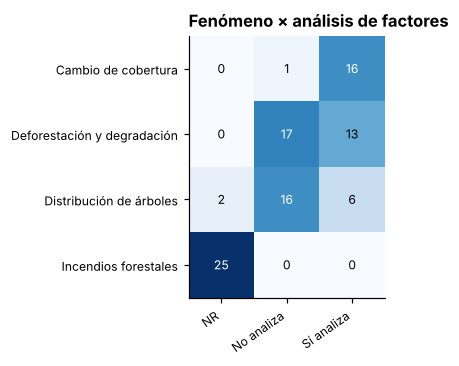

**Grupo de factor × fenómeno (n de estudios)**

fenomeno,Cambio de cobertura,Deforestación y degradación,Distribución de árboles
g,,,
Antrópicos,7,11,0
Cobertura / vegetación,11,2,1
Edáficos,0,0,3
Hidroclimáticos,3,1,2
Topográficos,2,1,4


In [ ]:
display(Markdown('**Analiza factores × fenómeno**')); _ = cruz('fenomeno','analiza_fact','Fenómeno × análisis de factores', key='O2_fen_x_analiza')
ex = con[['id_estudio','fenomeno','factores']].assign(g=con.factores.str.split(';')).explode('g').reset_index(drop=True); ex['g'] = ex.g.str.strip()
m = pd.crosstab(ex.g, ex.fenomeno); display(Markdown('**Grupo de factor × fenómeno (n de estudios)**')); display(m); TABLAS['O2_grupo_x_fen'] = m

In [ ]:
# factor_principal: texto libre en la mayoría. Se reportan los valores existentes y se asigna a un grupo con palabras clave (revisar a mano)
fp = df.loc[~df.factor_principal.fillna('NR').isin(['NR','No aplica']), ['id_estudio','fenomeno','factores','factor_principal','asociacion']]
print(f'factor_principal: {len(fp)} con dato | {(df.factor_principal=="No aplica").sum()} No aplica | {(df.factor_principal.fillna("NR")=="NR").sum()} NR')
display(fp)
TABLAS['O2_factor_principal'] = fp

factor_principal: 9 con dato | 34 No aplica | 53 NR


,id_estudio,fenomeno,factores,factor_principal,asociacion
1,E002,Distribución de árboles,Hidroclimáticos; Topográficos,Temperatura × precipitación,Mixta
3,E004,Distribución de árboles,Topográficos; Edáficos,ECa0.5; pendiente; elevación,NR
7,E008,Distribución de árboles,Topográficos,Heterogeneidad del hábitat / topografía,NR
8,E009,Distribución de árboles,NR,Heterogeneidad del sitio,NR
15,E016,Distribución de árboles,Hidroclimáticos; Cobertura / vegetación,Deforestación / degradación de la cobertura arbórea,Mixta
16,E017,Distribución de árboles,Topográficos; Edáficos,Elevación; convexidad; N y C del suelo,NR
21,E022,Distribución de árboles,NR,Perturbación,NR
23,E024,Distribución de árboles,Edáficos,Capacidad capilar de retención de agua del suelo,Positiva
60,E061,Cambio de cobertura,Hidroclimáticos; Topográficos; Antrópicos,Distancia a tierras abiertas,No evaluada


,n,% de 96,% de reportados
asociacion,,,
No evaluada,63,65.6,95.5
NR,30,31.3,NaN
Mixta,2,2.1,3.0
Positiva,1,1.0,1.5


NR = 30 de 96 (31 %). Reportados = 66.


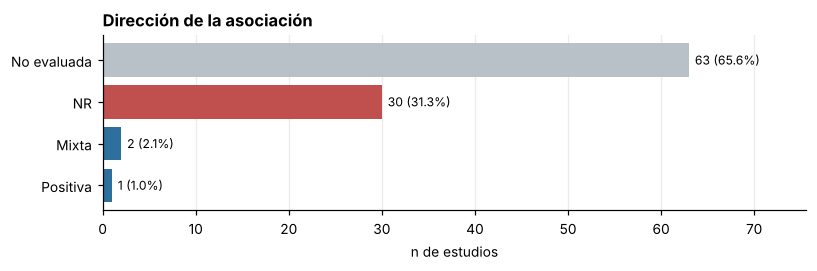

**Dirección de la asociación entre los estudios que analizan factores**

,n,% de 35,% de reportados
asociacion,,,
No evaluada,29,82.9,90.6
NR,3,8.6,NaN
Mixta,2,5.7,6.3
Positiva,1,2.9,3.1


NR = 3 de 35 (9 %). Reportados = 32.


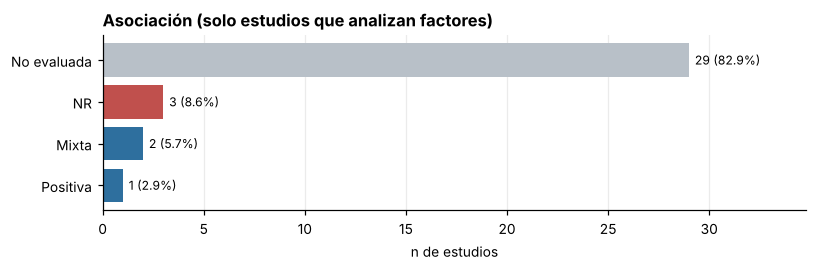

**Asociación entre los estudios que analizan factores, por fenómeno** (aclara qué es «No evaluada» y qué es NR)

asociacion,Mixta,NR,No evaluada,Positiva,Total
fenomeno,,,,,
Cambio de cobertura,0,0,16,0,16
Deforestación y degradación,0,0,13,0,13
Distribución de árboles,2,3,0,1,6
Total,2,3,29,1,35


**Asociación en TODOS los estudios, por fenómeno** (los NR se concentran en incendios)

asociacion,Mixta,NR,No evaluada,Positiva,Total
fenomeno,,,,,
Cambio de cobertura,0,0,17,0,17
Deforestación y degradación,0,0,30,0,30
Distribución de árboles,2,5,16,1,24
Incendios forestales,0,25,0,0,25
Total,2,30,63,1,96


In [ ]:
t_as = freq('asociacion','Dirección de la asociación', key='O2_asociacion')
con_f = df[df.analiza_fact=='Sí analiza']
display(Markdown('**Dirección de la asociación entre los estudios que analizan factores**')); t_as2 = freq('asociacion','Asociación (solo estudios que analizan factores)', data=con_f, key='O2_asociacion_con_factores')
display(Markdown('**Asociación entre los estudios que analizan factores, por fenómeno** (aclara qué es «No evaluada» y qué es NR)'))
_ = cruz('fenomeno','asociacion', 'Fenómeno × asociación (analizan factores)', data=con_f, key='O2_asoc_x_fen', plot=False)
display(Markdown('**Asociación en TODOS los estudios, por fenómeno** (los NR se concentran en incendios)'))
_ = cruz('fenomeno','asociacion', 'Fenómeno × asociación (todos)', key='O2_asoc_x_fen_todos', plot=False)

In [ ]:
g = t_fg
asoc_rep = ['Positiva','Negativa','Mixta','No significativa']
n_con = len(con_f)
a_rep = int(con_f.asociacion.isin(asoc_rep).sum()); a_noev = int((con_f.asociacion=='No evaluada').sum()); a_nr = int((con_f.asociacion.fillna('NR')=='NR').sum())
nr_asoc_tot = int((df.asociacion.fillna('NR')=='NR').sum()); nr_asoc_inc = int(((df.asociacion.fillna('NR')=='NR') & (df.fenomeno=='Incendios forestales')).sum())
n_hid = int(g.loc['Hidroclimáticos','n']) if 'Hidroclimáticos' in g.index else 0
R['O2'] = (f"{int((df.analiza_fact=='Sí analiza').sum())} de {N} estudios ({pc((df.analiza_fact=='Sí analiza').mean()*100)} %) analizan factores ambientales; {int((df.analiza_fact=='No analiza').sum())} no los analizan y {int((df.analiza_fact=='NR').sum())} están en NR "
           f"({', '.join(f'{v} de {k}' for k,v in df.loc[df.analiza_fact=='NR','fenomeno'].value_counts().items())}). Entre los que sí los analizan, los grupos más frecuentes son "
           + ', '.join(f"{k} ({v}, {pc(p)} %)" for k,v,p in zip(g.index[:3], g.n[:3], g['% de reportados'][:3]))
           + f". Los hidroclimáticos, que el PICO menciona primero, aparecen solo en {n_hid} de {n_con} estudios; Antrópicos y Edáficos no figuran en el PICO. Como los {int(((df.fenomeno=='Incendios forestales') & (df.analiza_fact=='NR')).sum())} estudios de incendios están en NR para factores, ese resultado está sesgado por falta de extracción, no por ausencia real. "
           f"Entre los {n_con} que analizan factores, la mayoría identifica factores pero no evalúa la dirección de la asociación: {a_noev} están «No evaluada», {a_rep} reportan una dirección y {a_nr} están en NR. "
           f"Los {nr_asoc_tot} NR de asociación en toda la matriz corresponden sobre todo a incendios ({nr_asoc_inc}). **No es posible concluir una dirección dominante.**")
display(Markdown('> **Respuesta O.2.** ' + R['O2']))

> **Respuesta O.2.** 35 de 96 estudios (36 %) analizan factores ambientales; 34 no los analizan y 27 están en NR (25 de Incendios forestales, 2 de Distribución de árboles). Entre los que sí los analizan, los grupos más frecuentes son Antrópicos (18, 51 %), Cobertura / vegetación (14, 40 %), Topográficos (7, 20 %). Los hidroclimáticos, que el PICO menciona primero, aparecen solo en 6 de 35 estudios; Antrópicos y Edáficos no figuran en el PICO. Como los 25 estudios de incendios están en NR para factores, ese resultado está sesgado por falta de extracción, no por ausencia real. Entre los 35 que analizan factores, la mayoría identifica factores pero no evalúa la dirección de la asociación: 29 están «No evaluada», 3 reportan una dirección y 3 están en NR. Los 30 NR de asociación en toda la matriz corresponden sobre todo a incendios (25). **No es posible concluir una dirección dominante.**

### O.3 Validación
Se evalúa **solo en estudios con modelo** (`tipo_problema` ≠ Descriptivo): en los descriptivos la validación no aplica.

Estudios con modelo (Clasificación o Regresión): 64 de 96


,n,% de 64,% de reportados
tec_validacion,,,
NR,61,95.3,NaN
Hold-out (entrenamiento / prueba),1,1.6,33.3
Validación espacial o por bloques,1,1.6,33.3
Validación cruzada k-fold,1,1.6,33.3


NR = 61 de 64 (95 %). Reportados = 3.


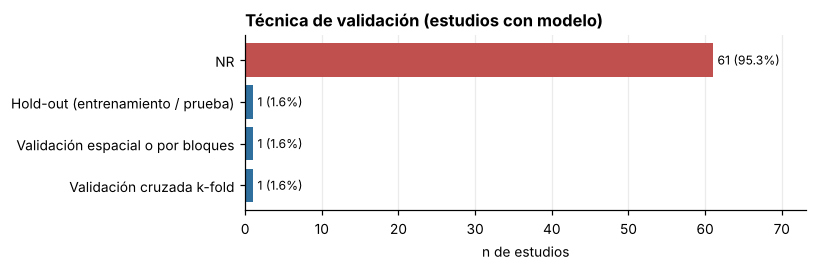

,n,% de 64,% de reportados
prop_validacion,,,
NR,60,93.8,NaN
No aplica (sin división),3,4.7,75.0
70/30,1,1.6,25.0


NR = 60 de 64 (94 %). Reportados = 4.


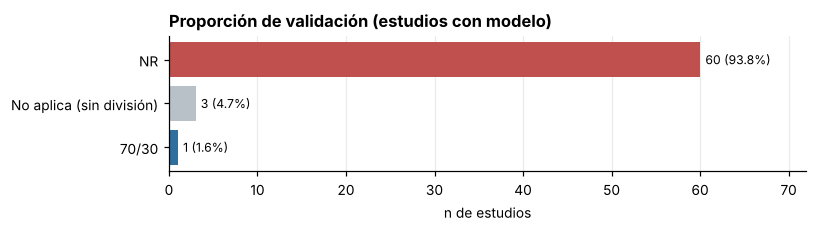

**Validación × tipo de problema** (todos los estudios)

tec_validacion,Datos independientes / verificación de campo,Hold-out (entrenamiento / prueba),NR,No aplica (descriptivo),Validación cruzada k-fold,Validación espacial o por bloques,Total
tipo_problema,,,,,,,
Clasificación,0,1,49,0,1,0,51
Descriptivo,1,0,0,31,0,0,32
Regresión,0,0,12,0,0,1,13
Total,1,1,61,31,1,1,96


In [ ]:
mod = df[df.tipo_problema!='Descriptivo']
print(f'Estudios con modelo (Clasificación o Regresión): {len(mod)} de {N}')
t_tv = freq('tec_validacion','Técnica de validación (estudios con modelo)', data=mod, key='O3_tec_validacion')
t_pv = freq('prop_validacion','Proporción de validación (estudios con modelo)', data=mod, key='O3_prop_validacion')
display(Markdown('**Validación × tipo de problema** (todos los estudios)')); _ = cruz('tipo_problema','tec_validacion','Tipo de problema × técnica de validación', key='O3_tipo_x_validacion', plot=False)

In [ ]:
v_ok = mod.tec_validacion.isin(['Hold-out (entrenamiento / prueba)','Validación cruzada k-fold','Validación espacial o por bloques','Validación temporal','Datos independientes / verificación de campo'])
nr_v = (mod.tec_validacion.fillna('NR')=='NR').sum(); ning = (mod.tec_validacion=='Ninguna').sum()
R['O3'] = (f"De {len(mod)} estudios con modelo, {int(v_ok.sum())} ({pc(v_ok.mean()*100)} %) reportan una técnica de validación, {int(ning)} declaran no validar y {int(nr_v)} ({pc(nr_v/len(mod)*100)} %) están en NR. "
           f"La proporción de partición está extraída en solo {int(mod.prop_validacion.isin(['70/30','80/20','75/25','60/40','Otra']).sum())} estudio(s). Ese NR masivo indica un vacío de extracción más que ausencia real de validación: no se puede identificar una técnica ni una proporción habitual hasta revisar el texto completo.")
display(Markdown('> **Respuesta O.3.** ' + R['O3']))

> **Respuesta O.3.** De 64 estudios con modelo, 3 (5 %) reportan una técnica de validación, 0 declaran no validar y 61 (95 %) están en NR. La proporción de partición está extraída en solo 1 estudio(s). Ese NR masivo indica un vacío de extracción más que ausencia real de validación: no se puede identificar una técnica ni una proporción habitual hasta revisar el texto completo.

### O.4 Desempeño
`metrica`, `valor_metrica`, `rango_valor`. Solo se resumen las **métricas estándar** (AUC, Exactitud global, Kappa, F1, R²). La categoría *Otra* mezcla magnitudes distintas (metros, proporciones de agregación, conteos…): se lista aparte y **no se promedia**.

,n,% de 96,% de reportados
metrica,,,
NR,45,46.9,NaN
Otra,20,20.8,39.2
No aplica (descriptivo),19,19.8,37.3
R²,4,4.2,7.8
AUC,4,4.2,7.8
Kappa,2,2.1,3.9
F1,1,1.0,2.0
Exactitud global,1,1.0,2.0


NR = 45 de 96 (47 %). Reportados = 51.


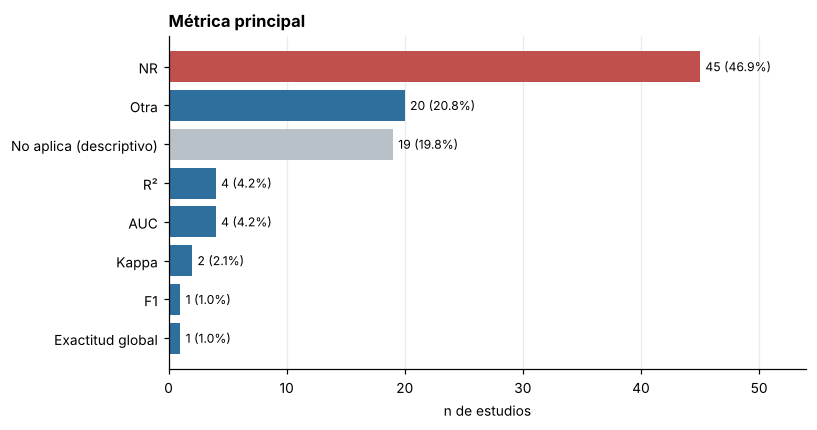

Con métrica estándar: 12 | con valor numérico: 12 | con valor no numérico o NR: 0


,n,mín,media,mediana,máx
metrica,,,,,
AUC,4,0.775,0.846,0.832,0.947
Exactitud global,1,0.910,0.910,0.910,0.910
Kappa,2,0.650,0.796,0.796,0.941
F1,1,0.870,0.870,0.870,0.870
R²,4,0.508,0.760,0.775,0.980


,id_estudio,fenomeno,tecnica_ppal,metodo,metrica,valor_metrica,rango_valor
70,E072,Incendios forestales,SIG multicriterio,AHP,AUC,0.799,Aceptable
72,E074,Incendios forestales,SIG multicriterio,AHP,AUC,0.864,Bueno
82,E084,Incendios forestales,SIG multicriterio,AHP,AUC,0.775,Aceptable
93,E095,Incendios forestales,Machine learning,Random Forest,AUC,0.9471,Excelente
94,E096,Incendios forestales,Clasificación y detección de cambios,Clasificación supervisada,Exactitud global,0.9102,Cumple el umbral
79,E081,Incendios forestales,Patrones de puntos,Ripley K,F1,0.87,Alto
64,E066,Cambio de cobertura,Machine learning,Random Forest,Kappa,0.941,Casi perfecto
95,E097,Cambio de cobertura,Clasificación y detección de cambios,Análisis multitemporal de cobertura,Kappa,0.65,Sustancial
3,E004,Distribución de árboles,Regresión espacial,"Rezago / error espacial (SAR, SEM)",R²,0.58,Moderado
69,E071,Cambio de cobertura,Clasificación y detección de cambios,Análisis multitemporal de cobertura,R²,0.9704,Alto


In [ ]:
t_me = freq('metrica','Métrica principal', key='O4_metrica')
est = ['AUC','Exactitud global','Kappa','F1','R²']
df['valor_num'] = pd.to_numeric(df.valor_metrica, errors='coerce')
e = df[df.metrica.isin(est)]
print(f'Con métrica estándar: {len(e)} | con valor numérico: {e.valor_num.notna().sum()} | con valor no numérico o NR: {e.valor_num.isna().sum()}')
g = e.groupby('metrica').valor_num.agg(n='count', mín='min', media='mean', mediana='median', máx='max').round(3).reindex(est).dropna(how='all'); display(g); TABLAS['O4_resumen_metricas'] = g
display(e[['id_estudio','fenomeno','tecnica_ppal','metodo','metrica','valor_metrica','rango_valor']].sort_values('metrica'))

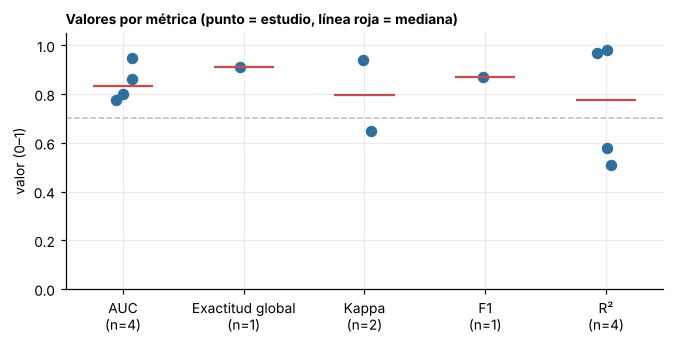

**Rango de interpretación** (`rango_valor`, umbrales de la ficha)

,n,% de 96,% de reportados
rango_valor,,,
NR,53,55.2,NaN
No aplica,19,19.8,44.2
Sin rango,12,12.5,27.9
Alto,3,3.1,7.0
Moderado,2,2.1,4.7
Aceptable,2,2.1,4.7
Casi perfecto,1,1.0,2.3
Bueno,1,1.0,2.3
Excelente,1,1.0,2.3


NR = 53 de 96 (55 %). Reportados = 43.


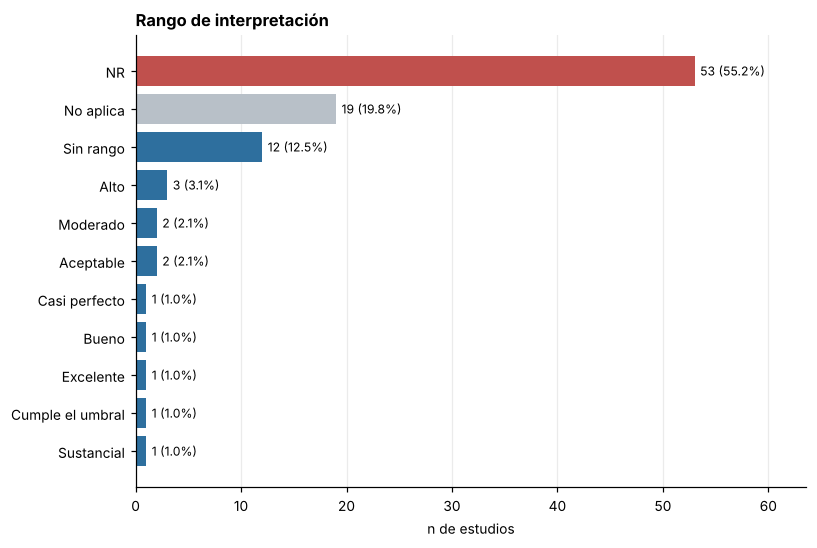

**«Otra» métrica — qué se reportó** (no comparable entre sí)

,id_estudio,fenomeno,metrica_otra,valor_metrica
0,E001,Distribución de árboles,Proporción de patrón agrupado,11.25
1,E002,Distribución de árboles,Altitud máxima del hábitat de baja idoneidad (2085),2329
5,E006,Distribución de árboles,Radio medio de clúster,3.89
8,E009,Distribución de árboles,Escala de agregación de Pinus koraiensis,10
9,E010,Distribución de árboles,Proporción mínima de la distancia analizada con patrón agregado,≈50
12,E013,Distribución de árboles,Proporción de asociaciones positivas/negativas,11% positivas (5 m); 13% negativas (16 m)
14,E015,Distribución de árboles,Árboles detectados,257 (bosque); 47 (área mixta)
16,E017,Distribución de árboles,Especies dominantes con agregación significativa,12/12
18,E019,Distribución de árboles,Exactitud de detección de patrones,70–86
22,E023,Distribución de árboles,Moran's I máximo,0.1644


In [ ]:
sub = e[e.valor_num.notna()]
if len(sub):
    fig, ax = plt.subplots(figsize=(6.2,3.2)); ordm = [m for m in est if m in sub.metrica.unique()]; rng = np.random.default_rng(1)
    for i,m in enumerate(ordm):
        v = sub.loc[sub.metrica==m,'valor_num']; ax.scatter(np.full(len(v),i)+rng.uniform(-.08,.08,len(v)), v, color=AZUL, s=42, zorder=3)
        ax.hlines(v.median(), i-.25, i+.25, color=ROJO, lw=1.5, zorder=4)
    ax.axhline(.7, color=GRIS, ls='--', lw=1); ax.set_xticks(range(len(ordm))); ax.set_xticklabels([f'{m}\n(n={int((sub.metrica==m).sum())})' for m in ordm])
    ax.set_ylim(0,1.05); ax.set_ylabel('valor (0–1)'); ax.set_title('Valores por métrica (punto = estudio, línea roja = mediana)', loc='left', fontweight='bold', fontsize=9); plt.tight_layout(); plt.show()
display(Markdown('**Rango de interpretación** (`rango_valor`, umbrales de la ficha)')); t_rv = freq('rango_valor','Rango de interpretación', key='O4_rango_valor')
display(Markdown('**«Otra» métrica — qué se reportó** (no comparable entre sí)'))
display(df.loc[df.metrica=='Otra',['id_estudio','fenomeno','metrica_otra','valor_metrica']].head(20))

In [ ]:
nm = int(e.valor_num.notna().sum()); hi = int(e.rango_valor.isin(['Alto','Bueno','Excelente','Casi perfecto','Sustancial','Cumple el umbral']).sum())
R['O4'] = (f"Solo {len(e)} estudios ({pc(len(e)/N*100)} %) reportan una métrica estándar, de los cuales {nm} tienen valor numérico en 0–1; {int((df.metrica=='Otra').sum())} usan una métrica «Otra» no comparable "
           f"y {int((df.metrica.fillna('NR')=='NR').sum())} están en NR. Entre las métricas estándar, "
           + '; '.join(f"{m}: n={int(r['n'])}, rango {r['mín']}–{r['máx']}" for m,r in g.iterrows())
           + f". {hi} de {len(e)} caen en categorías altas (Alto, Bueno, Excelente, Casi perfecto, Sustancial o Cumple el umbral). Con n tan pequeño estos valores son ilustrativos, no una estimación del desempeño típico.")
display(Markdown('> **Respuesta O.4.** ' + R['O4']))

> **Respuesta O.4.** Solo 12 estudios (13 %) reportan una métrica estándar, de los cuales 12 tienen valor numérico en 0–1; 20 usan una métrica «Otra» no comparable y 45 están en NR. Entre las métricas estándar, AUC: n=4, rango 0.775–0.947; Exactitud global: n=1, rango 0.91–0.91; Kappa: n=2, rango 0.65–0.941; F1: n=1, rango 0.87–0.87; R²: n=4, rango 0.508–0.98. 8 de 12 caen en categorías altas (Alto, Bueno, Excelente, Casi perfecto, Sustancial o Cumple el umbral). Con n tan pequeño estos valores son ilustrativos, no una estimación del desempeño típico.

### O.5 Calidad metodológica
`calidad_global` (Alta / Media / Baja).

> ⚠️ En la matriz v4 `calidad_global` está en **NR en los 96 estudios** (aún no valorada). Mientras no se complete, el notebook muestra un **indicador de apoyo**, la *completitud del reporte* (proporción de 12 campos clave con dato), que **no equivale a calidad metodológica**: mide cuánta información se pudo extraer, no si el estudio es riguroso. Cuando se llene `calidad_global`, las tablas de abajo se actualizan solas.

,n,% de 96,% de reportados
calidad_global,,,
NR,96,100.0,NaN


NR = 96 de 96 (100 %). Reportados = 0.


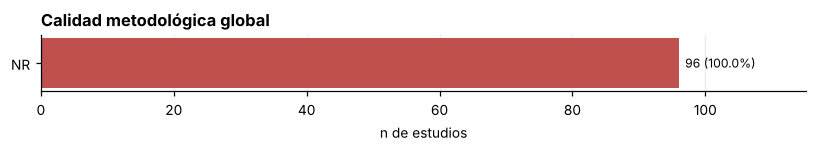

→ calidad_global sin valorar: se usa completitud del reporte como indicador de apoyo.


In [ ]:
t_cg = freq('calidad_global','Calidad metodológica global', key='O5_calidad')
if (df.calidad_global.fillna('NR')=='NR').all():
    print('→ calidad_global sin valorar: se usa completitud del reporte como indicador de apoyo.')
else:
    display(Markdown('**% por fenómeno**')); display((pd.crosstab(df.fenomeno, df.calidad_global, normalize='index').reindex(columns=['Alta','Media','Baja'],fill_value=0)*100).round(1))
    display(Markdown('**% por técnica principal**')); display((pd.crosstab(df.tecnica_ppal, df.calidad_global, normalize='index').reindex(columns=['Alta','Media','Baja'],fill_value=0)*100).round(1))

,n,media,mediana
fenomeno,,,
Incendios forestales,25,0.56,0.58
Cambio de cobertura,17,0.61,0.58
Deforestación y degradación,30,0.64,0.62
Distribución de árboles,24,0.93,1.00


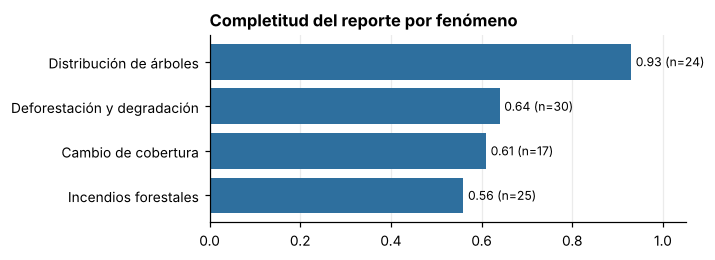

,n,media,mediana
tecnica_ppal,,,
Interpolación,4,0.52,0.54
Regresión espacial,5,0.55,0.58
SIG multicriterio,6,0.56,0.58
Clasificación y detección de cambios,25,0.60,0.58
Otra,3,0.61,0.58
Machine learning,15,0.63,0.58
Autocorrelación espacial,14,0.73,0.71
Patrones de puntos,24,0.89,1.00


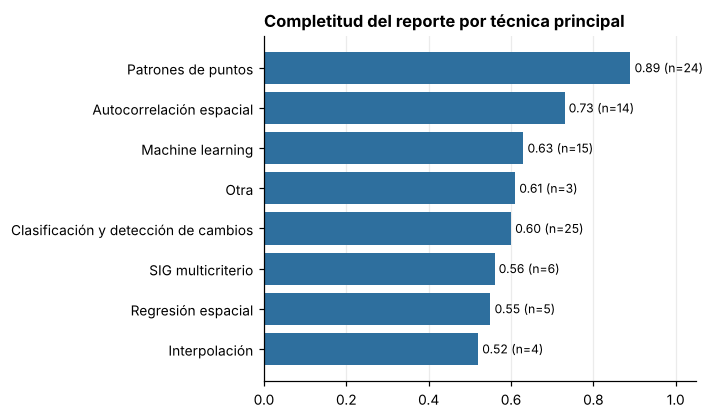

In [ ]:
for col, tit in [('fenomeno','Completitud del reporte por fenómeno'),('tecnica_ppal','Completitud del reporte por técnica principal')]:
    g = df.groupby(col).completitud.agg(n='count', media='mean', mediana='median').round(2).sort_values('media'); display(g); TABLAS[f'O5_completitud_{col}'] = g
    fig, ax = plt.subplots(figsize=(6.5, 0.36*len(g)+1)); ax.barh(g.index, g['media'], color=AZUL)
    for y,(v,n) in enumerate(zip(g['media'], g.n)): ax.text(v+.01, y, f'{v:.2f} (n={n})', va='center', fontsize=8)
    ax.set_xlim(0,1.05); ax.set_title(tit, loc='left', fontweight='bold'); ax.grid(axis='y', alpha=0); plt.tight_layout(); plt.show()

## Escala, resolución y calidad de los datos
La ficha v4 **ya no tiene columnas de escala ni resolución** (se eliminaron por baja cobertura; ver hoja `Cambios`). Con lo que sí hay en la matriz se puede aportar evidencia indirecta, **declarando que es un proxy**:

1. **Resolución espacial nominal del motor principal** (referencia general del sensor, no el valor que usó cada artículo). *Inventario/campo* y *estaciones* son **tipos de dato** y se separan: no tienen resolución de píxel.
2. **Dependencia de escala del patrón**: proporción de patrones «Mixto (cambia con la escala)».
3. **Origen del patrón mixto** por fenómeno, para no generalizar la dependencia de escala.
4. **Menciones** de escala, resolución, incertidumbre, sesgo o datos faltantes en `resultado_principal` y `observaciones` (búsqueda por palabras clave), incluyendo *sesgo/muestreo*, que el PICO pide evaluar.

,n,% de 96,% de reportados
resolucion_nominal,,,
Otra / sin dato,38,39.6,39.6
Datos de terreno (sin resolución de píxel),26,27.1,27.1
Media (≈30 m),19,19.8,19.8
Fina (≤10 m),8,8.3,8.3
Gruesa (≥250 m),5,5.2,5.2


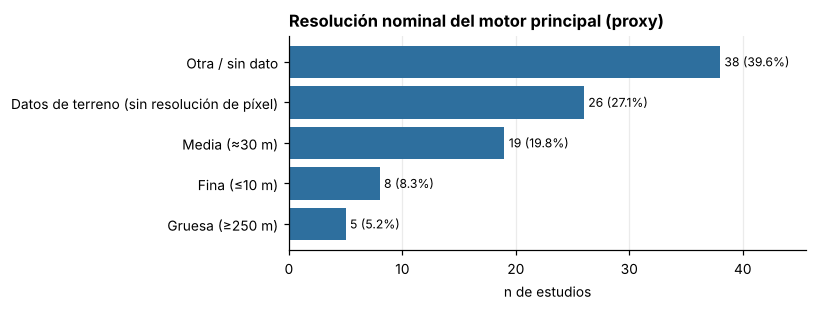

«Datos de terreno» (inventario/campo, estaciones) es un TIPO de dato, no una resolución: se excluye al buscar la resolución predominante.


**Resolución nominal solo entre sensores remotos / productos ráster** (n = 32)

,n,% de sensores remotos
resolucion_nominal,,
Media (≈30 m),19,59.4
Fina (≤10 m),8,25.0
Gruesa (≥250 m),5,15.6


**Resolución nominal × fenómeno**

fenomeno,Cambio de cobertura,Deforestación y degradación,Distribución de árboles,Incendios forestales,Total
resolucion_nominal,,,,,
Datos de terreno (sin resolución de píxel),0,0,20,6,26
Fina (≤10 m),3,3,0,2,8
Gruesa (≥250 m),1,0,0,4,5
Media (≈30 m),9,9,0,1,19
Otra / sin dato,4,18,4,12,38
Total,17,30,24,25,96


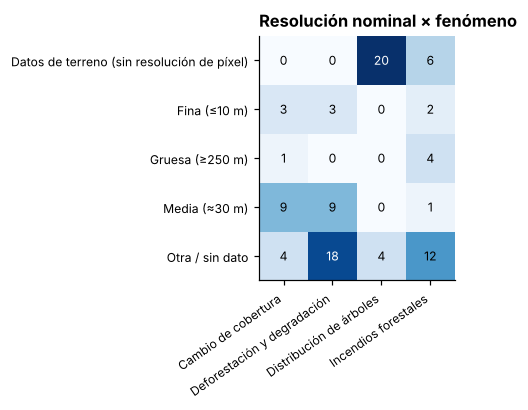

In [ ]:
RES = {'Sentinel-1':'Fina (≤10 m)','Sentinel-2':'Fina (≤10 m)','Landsat':'Media (≈30 m)','Hansen GFC':'Media (≈30 m)','DEM':'Media (≈30 m)',
       'MODIS':'Gruesa (≥250 m)','VIIRS / FIRMS':'Gruesa (≥250 m)','CHIRPS':'Gruesa (≥250 m)','WorldClim':'Gruesa (≥250 m)','ERA5':'Gruesa (≥250 m)','NASA POWER':'Gruesa (≥250 m)',
       'Inventario / campo':'Datos de terreno (sin resolución de píxel)','Estaciones':'Datos de terreno (sin resolución de píxel)','Otra':'Otra / sin dato','NR':'Otra / sin dato'}
df['resolucion_nominal'] = df.motor_ppal_n.map(RES).fillna('Otra / sin dato')
t_rn = freq('resolucion_nominal','Resolución nominal del motor principal (proxy)', key='E_resolucion')
print('«Datos de terreno» (inventario/campo, estaciones) es un TIPO de dato, no una resolución: se excluye al buscar la resolución predominante.')
sr = df[df.resolucion_nominal.str.startswith(('Fina','Media','Gruesa'))]
t_sr = sr.resolucion_nominal.value_counts().rename('n').to_frame(); t_sr['% de sensores remotos'] = r0(t_sr.n/len(sr)*100, 1)
display(Markdown(f'**Resolución nominal solo entre sensores remotos / productos ráster** (n = {len(sr)})')); display(t_sr); TABLAS['E_resolucion_sensores'] = t_sr
display(Markdown('**Resolución nominal × fenómeno**')); _ = cruz('resolucion_nominal','fenomeno','Resolución nominal × fenómeno', key='E_res_x_fen')

In [ ]:
# Dependencia de escala: entre estudios con patrón reportado
vp = df[df.patron.isin(['Agrupado','Aleatorio','Regular / disperso','Mixto (cambia con la escala)'])]
mx = (vp.patron=='Mixto (cambia con la escala)').sum()
print(f'Patrón mixto (cambia con la escala): {mx} de {len(vp)} estudios con patrón reportado ({pc(mx/len(vp)*100)} %)')
fen_mx = vp[vp.patron=='Mixto (cambia con la escala)'].fenomeno.value_counts()
display(Markdown('**Fenómeno de los estudios con patrón mixto**')); display(fen_mx.to_frame('n'))
print('Los patrones mixtos provienen solo de: ' + ', '.join(f'{k} ({v})' for k,v in fen_mx.items()) + ' → no se puede generalizar a incendios ni a deforestación.')

# Menciones por palabras clave (texto libre)
txt = (df.resultado_principal.fillna('')+' '+df.observaciones.fillna('')+' '+df.area_estudio.fillna('')).str.lower()
KW = {'Escala':r'escala|scale|multiescala','Resolución':r'resoluci[oó]n|resolution|píxel|pixel','Incertidumbre':r'incertidumbre|uncertaint','Sesgo / muestreo':r'sesgo|bias|muestreo','Datos faltantes':r'faltante|missing|nubes|cloud|vac[ií]o'}
kw = pd.DataFrame({k:{'n':int(txt.str.contains(p, regex=True).sum())} for k,p in KW.items()}).T; kw['% de 96'] = r0(kw.n/N*100, 1)
kw = kw.sort_values('n', ascending=False)
display(kw); TABLAS['E_menciones'] = kw
print('Solo detecta lo que quedó escrito en las columnas de texto; no sustituye la lectura del texto completo.')
print('El PICO promete extraer escala y resolución y evaluar calidad con una lista de verificación: esas columnas no existen y calidad_global está en NR en los 96 estudios.')

Patrón mixto (cambia con la escala): 9 de 18 estudios con patrón reportado (50 %)


**Fenómeno de los estudios con patrón mixto**

,n
fenomeno,
Distribución de árboles,9


Los patrones mixtos provienen solo de: Distribución de árboles (9) → no se puede generalizar a incendios ni a deforestación.


,n,% de 96
Escala,10,10.4
Datos faltantes,2,2.1
Resolución,1,1.0
Incertidumbre,0,0.0
Sesgo / muestreo,0,0.0


Solo detecta lo que quedó escrito en las columnas de texto; no sustituye la lectura del texto completo.
El PICO promete extraer escala y resolución y evaluar calidad con una lista de verificación: esas columnas no existen y calidad_global está en NR en los 96 estudios.


In [ ]:
sr_dom = t_sr.index[0]; top_kw = kw.index[0]
R['E'] = (f"La ficha v4 no registra escala ni resolución y `calidad_global` está en NR en los {N} estudios, por lo que esta parte de la pregunta (escala, resolución y sesgos con lista de verificación) **no puede responderse con evidencia directa**; solo hay proxies. "
          f"Entre los {len(sr)} estudios cuyo motor principal es un sensor o ráster, predomina la resolución «{sr_dom}» ({int(t_sr.loc[sr_dom,'n'])} de {len(sr)} estudios); «Datos de terreno» es un tipo de dato, no una resolución. "
          f"{mx} de {len(vp)} estudios con patrón reportado ({pc(mx/len(vp)*100)} %) muestran un patrón que cambia con la escala, pero todos son de {', '.join(fen_mx.index)}: el hallazgo no se extiende a otros fenómenos (incendios, deforestación, cobertura). "
          f"La mención textual más frecuente es «{top_kw}» ({int(kw.loc[top_kw,'n'])} estudios, {pc(kw.loc[top_kw,'% de 96'])} %), justo el aspecto que el PICO pide evaluar; escala: {kw.loc['Escala','n']}, resolución: {kw.loc['Resolución','n']}, incertidumbre: {kw.loc['Incertidumbre','n']}, datos faltantes: {kw.loc['Datos faltantes','n']}. "
          f"**Es la parte de la pregunta con menos evidencia en la matriz actual; la insuficiencia se debe a los NR, no a que estas prácticas no existan.**")
display(Markdown('> **Respuesta escala / resolución / calidad.** ' + R['E']))

> **Respuesta escala / resolución / calidad.** La ficha v4 no registra escala ni resolución y `calidad_global` está en NR en los 96 estudios, por lo que esta parte de la pregunta (escala, resolución y sesgos con lista de verificación) **no puede responderse con evidencia directa**; solo hay proxies. Entre los 32 estudios cuyo motor principal es un sensor o ráster, predomina la resolución «Media (≈30 m)» (19 de 32 estudios); «Datos de terreno» es un tipo de dato, no una resolución. 9 de 18 estudios con patrón reportado (50 %) muestran un patrón que cambia con la escala, pero todos son de Distribución de árboles: el hallazgo no se extiende a otros fenómenos (incendios, deforestación, cobertura). La mención textual más frecuente es «Escala» (10 estudios, 10 %), justo el aspecto que el PICO pide evaluar; escala: 10, resolución: 1, incertidumbre: 0, datos faltantes: 2. **Es la parte de la pregunta con menos evidencia en la matriz actual; la insuficiencia se debe a los NR, no a que estas prácticas no existan.**

## Anexo · Coherencia entre los resultados y el PICO
Resumen calculado de lo que **coincide** y de lo que **hay que corregir o aclarar en el PICO/protocolo** antes de redactar el artículo.

In [ ]:
nuc = int(df.tecnica_ppal.isin(NUCLEO_PICO).sum())
fac_pico = ['Hidroclimáticos','Topográficos','Cobertura / vegetación']
coh = pd.DataFrame([
 ['P · fenómenos y n', 'Coincide', ', '.join(f'{k} {v}' for k,v in df.fenomeno.value_counts().items()) + f' (total {N}); Perú {len(per)}'],
 ['I · técnicas del PICO', 'NO coincide', f'{nuc} de {N} estudios ({pc(nuc/N*100)} %) usan una de las 4 técnicas del PICO; técnica más frecuente: «{t_tec.index[0]}» ({int(t_tec.n.iloc[0])}). Ampliar o justificar la intervención; kernel no aparece entre los 15 métodos más frecuentes.'],
 ['O · factores', 'NO coincide', f'Más frecuente: «{t_fg.index[0]}» (no está en el PICO); hidroclimáticos en {n_hid} de {len(con)}; incendios en NR → sesgo de extracción.'],
 ['O · asociación', 'Corregido', f'{a_noev} «No evaluada», {a_rep} con dirección, {a_nr} NR entre los {n_con} que analizan factores.'],
 ['O · patrón espacial', 'Parcial', 'Solo Agrupado y Mixto; sin Aleatorio ni Regular; zonas de concentración y escala del patrón no extraídas.'],
 ['O · dependencia espacial', 'Parcial', f'{int(usan_stat.sum())} estudios usan Moran/LISA/Gi*; {int((usan_stat & ~df.dependencia.fillna("NR").isin(["NR","No evaluada"])).sum())} reportan dependencia; regla R7 agregada al control de calidad.'],
 ['Escala, resolución y sesgos', 'NO se puede responder', 'Sin columnas de escala/resolución y calidad_global en NR (96/96): solo evidencia indirecta.'],
 ['Fuentes y periodo', 'Documentar', 'plataforma = editorial (no son las bases Scopus/WoS/SciELO); periodo 2021–2026 no está en el PICO; 2026 incompleto.'],
], columns=['Elemento','Estado','Detalle'])
display(coh); TABLAS['Anexo_coherencia_PICO'] = coh

,Elemento,Estado,Detalle
0,P · fenómenos y n,Coincide,"Deforestación y degradación 30, Incendios forestales 25, Distribución de árboles 24, C..."
1,I · técnicas del PICO,NO coincide,48 de 96 estudios (50 %) usan una de las 4 técnicas del PICO; técnica más frecuente: «...
2,O · factores,NO coincide,Más frecuente: «Antrópicos» (no está en el PICO); hidroclimáticos en 6 de 35; incendio...
3,O · asociación,Corregido,"29 «No evaluada», 3 con dirección, 3 NR entre los 35 que analizan factores."
4,O · patrón espacial,Parcial,Solo Agrupado y Mixto; sin Aleatorio ni Regular; zonas de concentración y escala del p...
5,O · dependencia espacial,Parcial,11 estudios usan Moran/LISA/Gi*; 3 reportan dependencia; regla R7 agregada al control ...
6,"Escala, resolución y sesgos",NO se puede responder,Sin columnas de escala/resolución y calidad_global en NR (96/96): solo evidencia indir...
7,Fuentes y periodo,Documentar,plataforma = editorial (no son las bases Scopus/WoS/SciELO); periodo 2021–2026 no está...


## Síntesis: respuesta a la pregunta de la revisión
Texto generado desde los datos; sirve de base para la redacción de resultados (revisar antes de citar).

In [ ]:
sint = pd.DataFrame([
 ['P · ¿Qué fenómeno y dónde?',                         R['P']],
 ['I · ¿Qué técnica y qué motor de datos?',             R['I']],
 ['O · ¿Qué patrones espaciales se reportan?',          R['O1']],
 ['O · ¿Qué factores ambientales se asocian?',          R['O2']],
 ['O · ¿Cómo se valida?',                               R['O3']],
 ['O · ¿En qué rango están los valores?',               R['O4']],
 ['Escala, resolución y calidad de los datos',          R['E']],
], columns=['Sub-pregunta','Respuesta'])
for _, r in sint.iterrows(): display(Markdown(f"**{r['Sub-pregunta']}**\n\n{r['Respuesta']}\n"))
TABLAS['Sintesis'] = sint

**P · ¿Qué fenómeno y dónde?**

Los 96 estudios se reparten así: Deforestación y degradación (30), Incendios forestales (25), Distribución de árboles (24), Cambio de cobertura (17). El continente más estudiado es Asia (43, 48 % de los reportados), seguido de América del Sur (25); el país más frecuente es CHN (20) y luego PER (11). El subgrupo Perú reúne 11 estudios (11 %): 7 usan clasificación y detección de cambios y ninguno usa patrones de puntos ni autocorrelación espacial como técnica principal (0 y 0), lo que sustenta el vacío de investigación (research gap) en el país.


**I · ¿Qué técnica y qué motor de datos?**

La técnica principal más usada es «Clasificación y detección de cambios» (25 estudios, 26 %), seguida de Patrones de puntos (24) y Machine learning (15). 53 % de los estudios son de clasificación y 33 % solo describen el patrón; la regresión es minoritaria (14 %). Solo 21 estudios (22 %) combinan una técnica secundaria. Motor principal más frecuente entre los reportados: «Inventario / campo» (24, 30 %); 17 estudios no lo reportan y 21 usan una fuente fuera de la lista cerrada. Solo 48 de 96 estudios (50 %) usan como técnica principal una de las 4 del PICO (patrones de puntos, autocorrelación, interpolación, SIG); los otros 48 son técnicas fuera de la intervención definida (clasificación y detección de cambios, machine learning, regresión espacial, otra), por lo que el PICO debe ampliarse o justificarse. El kernel mencionado en el PICO no aparece entre los 15 métodos más frecuentes.


**O · ¿Qué patrones espaciales se reportan?**

Solo 36 de 96 estudios (38 %) aplican un estadístico de patrón; entre los estadísticos de la lista, el más usado es «Ripley K / L» (7), y 18 usan «Otro» (estadísticos fuera de la lista). De los 36, 15 no tienen el patrón extraído (NR). Entre los 18 con patrón reportado: Mixto (cambia con la escala) 9, Agrupado 9. Los patrones extraídos son solo Agrupado y Mixto; no hay ninguno Aleatorio ni Regular/disperso, y las zonas de concentración y la escala del patrón no se extrajeron. De 11 estudios que usan Moran, LISA o Gi*, solo 3 reportan la dependencia espacial (8 en NR); ninguno reporta negativa ni no significativa.


**O · ¿Qué factores ambientales se asocian?**

35 de 96 estudios (36 %) analizan factores ambientales; 34 no los analizan y 27 están en NR (25 de Incendios forestales, 2 de Distribución de árboles). Entre los que sí los analizan, los grupos más frecuentes son Antrópicos (18, 51 %), Cobertura / vegetación (14, 40 %), Topográficos (7, 20 %). Los hidroclimáticos, que el PICO menciona primero, aparecen solo en 6 de 35 estudios; Antrópicos y Edáficos no figuran en el PICO. Como los 25 estudios de incendios están en NR para factores, ese resultado está sesgado por falta de extracción, no por ausencia real. Entre los 35 que analizan factores, la mayoría identifica factores pero no evalúa la dirección de la asociación: 29 están «No evaluada», 3 reportan una dirección y 3 están en NR. Los 30 NR de asociación en toda la matriz corresponden sobre todo a incendios (25). **No es posible concluir una dirección dominante.**


**O · ¿Cómo se valida?**

De 64 estudios con modelo, 3 (5 %) reportan una técnica de validación, 0 declaran no validar y 61 (95 %) están en NR. La proporción de partición está extraída en solo 1 estudio(s). Ese NR masivo indica un vacío de extracción más que ausencia real de validación: no se puede identificar una técnica ni una proporción habitual hasta revisar el texto completo.


**O · ¿En qué rango están los valores?**

Solo 12 estudios (13 %) reportan una métrica estándar, de los cuales 12 tienen valor numérico en 0–1; 20 usan una métrica «Otra» no comparable y 45 están en NR. Entre las métricas estándar, AUC: n=4, rango 0.775–0.947; Exactitud global: n=1, rango 0.91–0.91; Kappa: n=2, rango 0.65–0.941; F1: n=1, rango 0.87–0.87; R²: n=4, rango 0.508–0.98. 8 de 12 caen en categorías altas (Alto, Bueno, Excelente, Casi perfecto, Sustancial o Cumple el umbral). Con n tan pequeño estos valores son ilustrativos, no una estimación del desempeño típico.


**Escala, resolución y calidad de los datos**

La ficha v4 no registra escala ni resolución y `calidad_global` está en NR en los 96 estudios, por lo que esta parte de la pregunta (escala, resolución y sesgos con lista de verificación) **no puede responderse con evidencia directa**; solo hay proxies. Entre los 32 estudios cuyo motor principal es un sensor o ráster, predomina la resolución «Media (≈30 m)» (19 de 32 estudios); «Datos de terreno» es un tipo de dato, no una resolución. 9 de 18 estudios con patrón reportado (50 %) muestran un patrón que cambia con la escala, pero todos son de Distribución de árboles: el hallazgo no se extiende a otros fenómenos (incendios, deforestación, cobertura). La mención textual más frecuente es «Escala» (10 estudios, 10 %), justo el aspecto que el PICO pide evaluar; escala: 10, resolución: 1, incertidumbre: 0, datos faltantes: 2. **Es la parte de la pregunta con menos evidencia en la matriz actual; la insuficiencia se debe a los NR, no a que estas prácticas no existan.**


## Exportar tablas

In [ ]:
SALIDA = 'Grupo10_Resultados_Descriptivos.xlsx'
with pd.ExcelWriter(SALIDA) as xw:
    for k, t in TABLAS.items():
        t.to_excel(xw, sheet_name=k[:31], index=not isinstance(t.index, pd.RangeIndex))
print(f'{len(TABLAS)} tablas guardadas en {SALIDA}') 

65 tablas guardadas en Grupo10_Resultados_Descriptivos.xlsx
